In [1]:
# 参考链接： https://www.kaggle.com/code/abhayparashar31/titanic-complete-analysis-prediction/notebook#Model-Training

> **每个代码单元后面都跟着一个「预期输出」单元**：文字输出逐字摘录，图片导出到本目录 `assets/` 并以相对路径引用，因此执行 **Kernel → Clear All Outputs** 之后仍然看得见这次实跑的结果。
>
> 这里保存的输出来自**课堂环境 `~/env_dl_uv`（Python 3.12.12 + scikit-learn 1.7.2，XGBoost 3.4.1 / LightGBM 4.7.0）的实跑**：课堂默认参数、CPU、各模型固定随机种子，端到端 **84.82 s**。模型对比表第一名 **SVM（10 折 CV 0.8146）**；GridSearchCV 调优确认默认 `C=1, gamma='scale', kernel='rbf'` 已是最优（CV 82.13%，测试集 81.78%）；Pipeline + GridSearchCV 最佳 CV **82.18%**；XGBoost CV **82.38%**、LightGBM CV **82.71%**；ONNX 导出后用 onnxruntime 推理，与 sklearn 原生预测逐位一致。
>
> 运行会生成并被 Git 忽略的产物：`models/`（pkl/onnx）、`result/Submission.csv`、`Submission_SVM_Pipeline.csv`、`tmp.csv`；写出单元已自带 `mkdir`，空目录也能直接跑通。刷新本实跑（仓库根目录，先执行、再内嵌）：
> - `~/env_dl_uv/.venv/bin/python english/scripts/execute_and_save.py --group ml --language zh-CN --cwd module`
> - `~/env_dl_uv/.venv/bin/python scripts/embed_expected_outputs.py --module 00-machine-learning`

In [2]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "请选择项目的 Python 3.12 内核。"
assert version('scikit-learn').split("+")[0] == '1.7.2', "请选择项目锁定的运行环境。"
print("Python：", sys.version.split()[0])
print('scikit-learn' + "：", version('scikit-learn'))
print("运行模式：", '课堂默认训练参数')

Python： 3.12.12
scikit-learn： 1.7.2
运行模式： 课堂默认训练参数


**预期输出：**

```text
Python： 3.12.12
scikit-learn： 1.7.2
运行模式： 课堂默认训练参数
```

# Titanic 生存预测：从零到一的机器学习完整项目

本 Notebook 以 Kaggle 经典的 **Titanic 生存预测**竞赛为案例，带你走完一个机器学习项目的完整流程。你将从原始数据出发，经历探索性数据分析、数据预处理、特征工程、多模型对比、超参数调优，最终掌握如何用 Pipeline 构建工业级的可复用工作流。

---

## 学习目标

完成本章学习后，你将能够：

- 理解 EDA（探索性数据分析）的目的和常用方法
- 处理数据缺失值、异常值和类别特征编码
- 掌握特征工程的基本技巧（分桶、组合特征、标准化）
- 对比多种分类算法的性能（朴素贝叶斯、SVM、KNN、逻辑回归、随机森林、AdaBoost）
- 使用交叉验证和网格搜索进行模型评估与调优
- 理解 Pipeline 的价值，并能用 `ColumnTransformer` + `Pipeline` 构建端到端工作流
- 掌握模型的保存、加载和部署方式（pickle / joblib / ONNX）

---

## 前置知识

- Python 基础（列表、字典、函数、文件操作）
- `pandas` 和 `numpy` 的基本用法
- 简单的 `matplotlib` / `seaborn` 可视化
- 了解机器学习的基本概念（训练集/测试集、特征/标签、过拟合/欠拟合）

---

## 数据集说明

本项目使用两个 CSV 文件（位于 `./titanic/` 目录）：

| 文件 | 行数 | 说明 |
|------|------|------|
| `LabeledData.csv` | 891 | 训练数据，含 `Survived` 标签（0=死亡，1=存活） |
| `UnlabeledData.csv` | 418 | 测试数据，无标签，用于最终预测提交 |

关键字段：
- `Pclass`：船舱等级（1=头等舱，2=二等舱，3=三等舱）
- `Sex`：性别
- `Age`：年龄（含缺失值）
- `SibSp`：兄弟姐妹/配偶数量
- `Parch`：父母/子女数量
- `Fare`：票价
- `Embarked`：登船港口（S/C/Q）
- `Cabin`：舱位号（缺失率约 77%，后续将丢弃）

---

## Notebook 结构导览

建议按顺序执行，各章节之间存在一定的状态依赖：

1. **数据准备** — 加载数据、了解字段含义
2. **EDA 探索性数据分析** — 可视化各特征与生存率的关系，发现数据规律
3. **数据预处理** — 缺失值处理、删除无关列
4. **特征工程** — 编码、特征组合、标准化
5. **模型训练与对比** — 6 种分类算法 + 交叉验证
6. **超参数调优** — GridSearchCV 寻找最优参数
7. **模型的保存与部署** — pickle / joblib / ONNX 三种方式
8. **Pipeline：构建可复用的机器学习工作流** — 工业级最佳实践
9. **算法扩展对比** — XGBoost / LightGBM

> 提示：本 Notebook 中的代码片段均可在各自独立的虚拟环境中运行。建议在执行前确保已安装 `requirements.txt` 中的依赖。


# 数据准备

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import warnings
warnings.filterwarnings('ignore')

## 加载数据集

在机器学习中，数据集是指用于训练、验证和测试机器学习模型的数据的集合。数据集通常包含两个部分：特征（输入数据）和标签（输出数据）。下面我会详细介绍机器学习中常见的几种数据集：  

**训练数据集（Training Dataset）：**  
训练数据集是用于训练机器学习模型的数据集。  
包含了特征和对应的标签。  
模型通过学习训练数据集中的模式、关系和规律来进行训练。  
**测试数据集（Test Dataset）：**  
测试数据集用于最终评估模型的性能和泛化能力。  
保持未见过的数据，用于评估模型在真实世界数据上的表现。  
在模型训练和超参数调优完成后，使用测试数据集进行最终性能评估。  
**无标签数据集（Unlabeled Dataset）：**  
无标签数据集只包含特征信息，缺少对应的标签信息。  

还会涉及到验证集
**验证数据集（Validation Dataset）：**  
验证数据集用于评估模型的性能和调优超参数。  
通常从训练数据集中分出一部分作为验证数据集。  
模型在验证数据集上进行评估，以便及时发现模型是否出现过拟合或欠拟合，并选择最佳的超参数设置。  

数据集链接：

In [5]:
df_labeled = pd.read_csv ('titanic/LabeledData.csv')
df_unLabeled = pd.read_csv('titanic/UnlabeledData.csv')

In [6]:
df_labeled.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**预期输出：**

```text
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S
```

In [7]:
df_unLabeled.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


**预期输出：**

```text
   PassengerId  Pclass                                          Name     Sex  \
0          892       3                              Kelly, Mr. James    male   
1          893       3              Wilkes, Mrs. James (Ellen Needs)  female   
2          894       2                     Myles, Mr. Thomas Francis    male   
3          895       3                              Wirz, Mr. Albert    male   
4          896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female   

    Age  SibSp  Parch   Ticket     Fare Cabin Embarked  
0  34.5      0      0   330911   7.8292   NaN        Q  
1  47.0      1      0   363272   7.0000   NaN        S  
2  62.0      0      0   240276   9.6875   NaN        Q  
3  27.0      0      0   315154   8.6625   NaN        S  
4  22.0      1      1  3101298  12.2875   NaN        S
```

In [8]:
df_labeled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**预期输出：**

```text
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
```

In [9]:
## Checking for  the number of rows and columns  in the dataset
# 检查数据集中的行数和列数
print(f"Number of rows :{df_labeled.shape[0]} \nNumber of columns:{df_labeled.shape[1]}")

Number of rows :891 
Number of columns:12


**预期输出：**

```text
Number of rows :891 
Number of columns:12
```

| 序号 | 字段名          | 类型    | 缺失值情况        | 中文解释                                                     |
| ---- | --------------- | ------- | ----------------- | ------------------------------------------------------------ |
| 0    | **PassengerId** | int64   | 无                | 乘客编号（唯一标识，用于索引，无实际预测意义）               |
| 1    | **Survived**    | int64   | 无                | 是否存活（目标变量，0 = 未生还，1 = 生还）                   |
| 2    | **Pclass**      | int64   | 无                | 客舱等级（1 = 一等舱，2 = 二等舱，3 = 三等舱，社会经济地位的 proxy） |
| 3    | **Name**        | object  | 无                | 姓名（可衍生称呼 Title，如 Mr, Miss, Dr，有预测价值）        |
| 4    | **Sex**         | object  | 无                | 性别（male/female，强预测因子之一）                          |
| 5    | **Age**         | float64 | 177 缺失          | 年龄（数值型，可分箱或加“是否儿童”特征）                     |
| 6    | **SibSp**       | int64   | 无                | 同行的兄弟姐妹/配偶数量（家庭结构相关）                      |
| 7    | **Parch**       | int64   | 无                | 同行的父母/子女数量（家庭结构相关）                          |
| 8    | **Ticket**      | object  | 无                | 船票号（可解析出某些分组模式，但原始值意义不大）             |
| 9    | **Fare**        | float64 | 无（test 有缺失） | 票价（与舱位/财富相关，长尾分布，需 log 变换或标准化）       |
| 10   | **Cabin**       | object  | 687 缺失          | 舱号（信息量大，但缺失严重；可提取首字母 A/B/C…，对应不同甲板） |
| 11   | **Embarked**    | object  | 2 缺失            | 登船港口（C = Cherbourg，Q = Queenstown，S = Southampton；需 one-hot） |

## EDA

什么是EDA？ 
在kaggle社区经常会遇到EDA这个词。EDA的全称是Exploratory Data Analysis，是一种探索式的数据分析，  

探索性数据分析（EDA）是由数据科学家用来分析和调查数据集，并总结其主要特征，通常采用数据可视化方法。  
它有助于确定如何最好地操作数据源以获得你所需要的答案，使数据科学家更容易发现模式，发现异常，测试一个假设，或检查假设。  

EDA的主要目的是目的是为了理解你的数据、做出任何假设之前帮助观察数据。它可以帮助识别明显的错误，以及更好地理解数据中的模式，检测异常值或异常事件，找到变量间的有趣关系。  

通过总结数据的主要特征、绘制图表从而更形象生动的理解。  
常用的作图方法有：直方图（Histograms），箱形图（Box plot），散点图（Scatter plot）等等。  

为什么要做探索性数据分析？

对数据集更深的理解（分布、缺失等统计信息）  
获得高质量的数据集（异常值、缺失值的基本处理）  
机器学习模型、实证假设构建的思路（灵感）  

In [10]:
# 查看数据集的列
df_labeled.columns
# 查看各个元素和Survived的关系

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

**预期输出：**

```text
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')
```

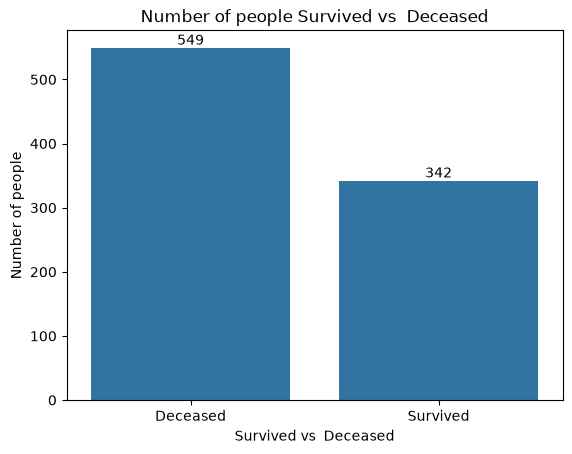

In [11]:
# Survived
ax = sns.countplot(data=df_labeled, x = 'Survived');  # countplot是seaborn库中分类图的一种，作用是使用条形显示每个分箱器中的观察计数
ax.bar_label(ax.containers[0]) # 在柱状图上显示y的数值，取出AxesSubplot对象的containers属性，得到container对象的迭代器，遍历其或单独取出container对象传给plt.bar_label

plt.title("Number of people Survived vs  Deceased")
plt.xlabel("Survived vs  Deceased")
plt.ylabel("Number of people")
plt.xticks(ticks=[0,1],labels=['Deceased','Survived'])
plt.show();

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-1.png)

*为什么要做探索性数据分析？*

In [12]:
# Age
df_labeled.Age.mean()

29.69911764705882

**预期输出：**

```text
29.69911764705882
```

In [13]:
# EDA 阶段创建临时副本，不修改原始数据
eda_temp = df_labeled.copy()
eda_temp['Age'] = eda_temp['Age'].fillna(eda_temp['Age'].mean())  # 使用mean值填充Age的NAN值
eda_temp['Age'] = eda_temp['Age'].astype(int)
eda_temp['Age']


0      22
1      38
2      26
3      35
4      35
       ..
886    27
887    19
888    29
889    26
890    32
Name: Age, Length: 891, dtype: int64

**预期输出：**

```text
0      22
1      38
2      26
3      35
4      35
       ..
886    27
887    19
888    29
889    26
890    32
Name: Age, Length: 891, dtype: int64
```

In [14]:
# 将eda_temp进行拷贝
temp = eda_temp.copy()


In [15]:
# 根据不同年龄段，打上不同的标签
temp['Age'] = pd.cut(temp['Age'], bins = [0,12,20,40,120],labels=['Children','Teenage','Adult','Elder'])

[Text(0, 0, '62'), Text(0, 0, '111'), Text(0, 0, '563'), Text(0, 0, '148')]

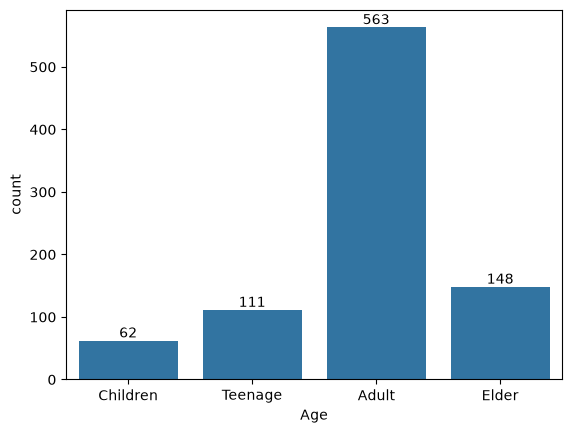

In [16]:
# 根据年龄段进行数据可视化
ax = sns.countplot(data = temp, x='Age')
ax.bar_label(ax.containers[0])

**预期输出：**

```text
[Text(0, 0, '62'), Text(0, 0, '111'), Text(0, 0, '563'), Text(0, 0, '148')]
```

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-2.png)

*为什么要做探索性数据分析？*

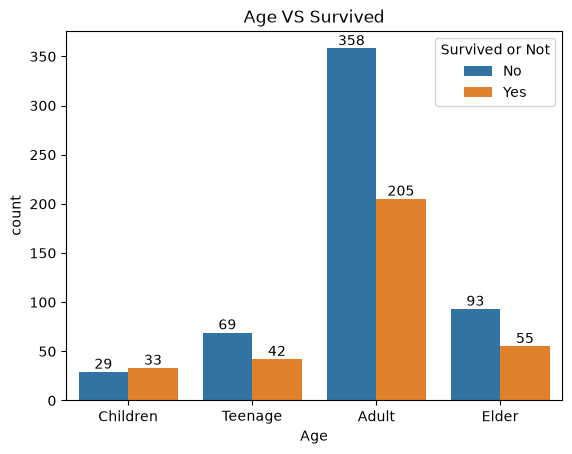

In [17]:
# 统计每个年龄段surived和not surived 的人数
ax=sns.countplot(data = temp, x = 'Age',hue= 'Survived')  
# data：df或array或array列表，用于绘图的数据集，x或y缺失时，data参数为数据集，同时x或y不可缺少，必须要有其中一个
# x： x轴上的条形图，以x标签划分统计个数
# hue：在x或y标签划分的同时，再以hue标签划分统计个数
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not',loc='upper right',labels=['No','Yes']);
plt.title('Age VS Survived')
plt.show()

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-3.png)

*为什么要做探索性数据分析？*

In [18]:
# 票价fare
# 票价的平均值
temp['Fare'].mean()

32.204207968574636

**预期输出：**

```text
32.204207968574636
```

<Axes: >

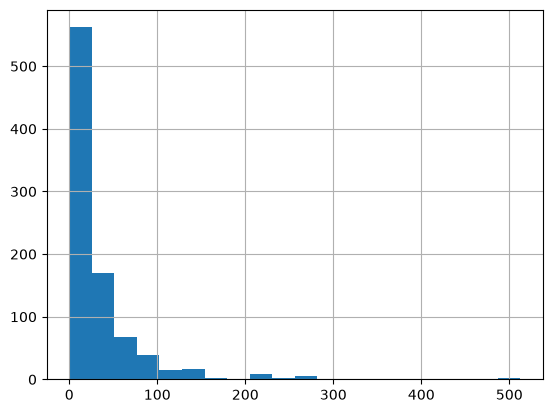

In [19]:
temp['Fare'].hist(bins=20)  # Pandas的画图函数：df.hist()

**预期输出：**

```text
<Axes: >
```

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-4.png)

*为什么要做探索性数据分析？*

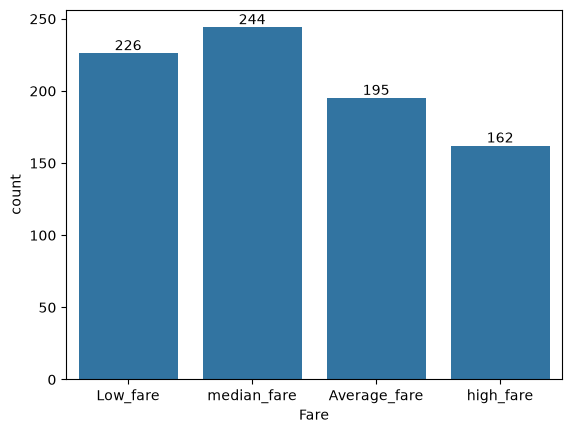

In [20]:
# 根据票价，分为四个分段 
temp['Fare'] = pd.cut(temp['Fare'], bins=[0,8,16,32,110], labels=['Low_fare','median_fare','Average_fare','high_fare'])
ax = sns.countplot(data=temp, x='Fare')
ax.bar_label(ax.containers[0]);

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-5.png)

*为什么要做探索性数据分析？*

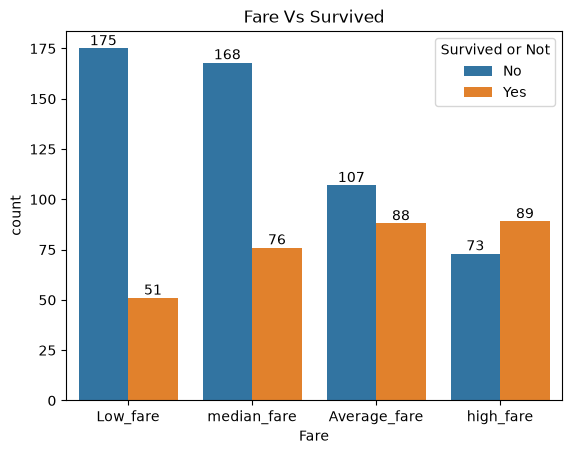

In [21]:
# 各个票价分段，存活和死亡的人数
ax = sns.countplot(data=temp, x='Fare',hue='Survived')
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not', loc='upper right', labels=['No', 'Yes']);
plt.title('Fare Vs Survived')
plt.show();

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-6.png)

*为什么要做探索性数据分析？*

In [22]:
# Cabin座位信息
nullCabin = temp.Cabin.isna().sum()
nullCabin

687

**预期输出：**

```text
687
```

In [23]:
temp['Cabin']

0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: object

**预期输出：**

```text
0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: object
```

In [24]:
# 座位信息缺失严重
str(round(nullCabin/(len(temp))*100,2))+"% Null Values"
# 有这么多空值，所以最好放弃它。

'77.1% Null Values'

**预期输出：**

```text
'77.1% Null Values'
```

In [25]:
# 仓位等级 Pclass : Passenger Class
temp.Pclass.unique()

array([3, 1, 2])

**预期输出：**

```text
array([3, 1, 2])
```

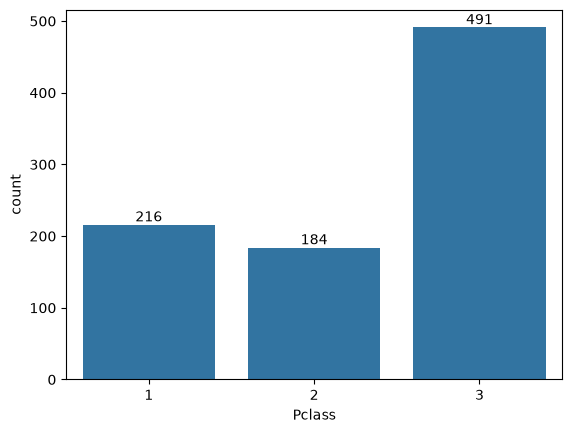

In [26]:
ax = sns.countplot(data=temp,x='Pclass');
ax.bar_label(ax.containers[0]);

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-7.png)

*为什么要做探索性数据分析？*

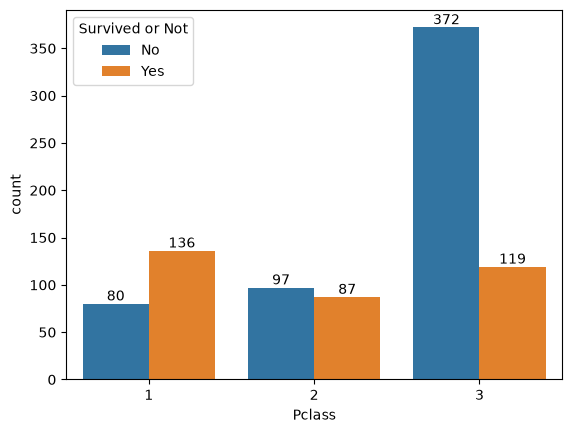

In [27]:
ax = sns.countplot(data=temp,x='Pclass',hue='Survived');
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not', loc='upper left', labels=['No', 'Yes']);

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-8.png)

*为什么要做探索性数据分析？*

In [28]:
# Sex
# 查看Sex的值有哪些
temp.Sex.unique()

array(['male', 'female'], dtype=object)

**预期输出：**

```text
array(['male', 'female'], dtype=object)
```

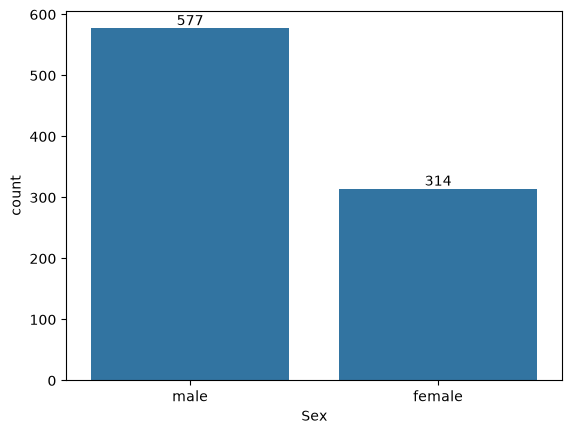

In [29]:
# 查看性别的分布情况
ax = sns.countplot(data=temp,x='Sex');
ax.bar_label(ax.containers[0]);

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-9.png)

*为什么要做探索性数据分析？*

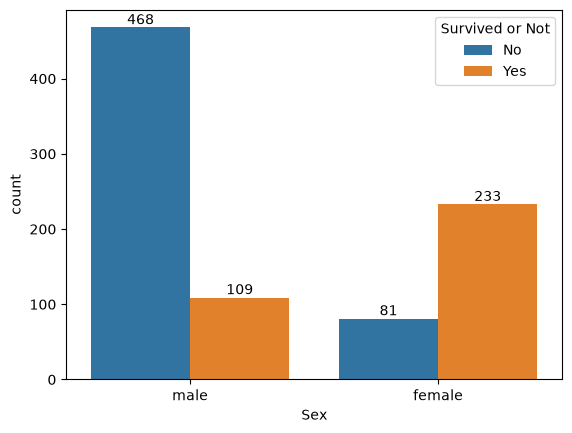

In [30]:
# 性别与存货的关系
# Sex vs Survived
ax = sns.countplot(data=temp,x='Sex',hue='Survived');
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not', loc='upper right', labels=['No', 'Yes']);

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-10.png)

*为什么要做探索性数据分析？*

In [31]:
# SibSp : 泰坦尼克号上的兄弟姐妹/配偶的数量
temp.SibSp.unique()

array([1, 0, 3, 4, 2, 5, 8])

**预期输出：**

```text
array([1, 0, 3, 4, 2, 5, 8])
```

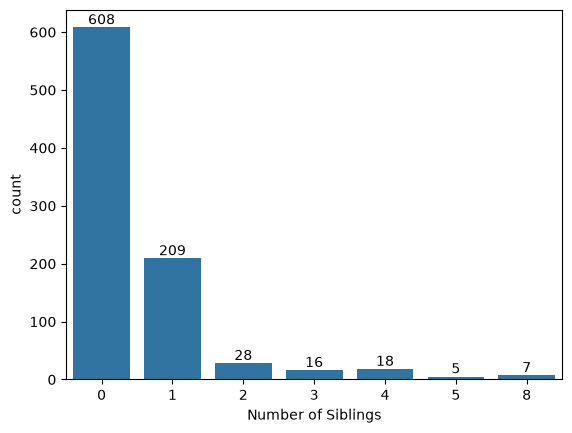

In [32]:
#  泰坦尼克号上的兄弟姐妹/配偶的数量 分布
ax = sns.countplot(data=temp,x='SibSp');
ax.bar_label(ax.containers[0]);
ax.set_xlabel('Number of Siblings');

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-11.png)

*为什么要做探索性数据分析？*

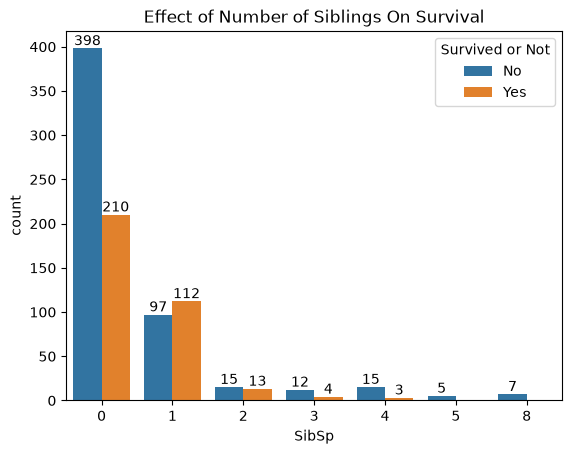

In [33]:
# Number of Siblings vs Survived
# 兄弟姐妹、配偶数量与是否存货的关系
ax = sns.countplot(data=temp,x='SibSp',hue='Survived');
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not', loc='upper right', labels=['No', 'Yes']);
plt.title('Effect of Number of Siblings On Survival')
plt.show();

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-12.png)

*为什么要做探索性数据分析？*

In [34]:
# Parch: 泰坦尼克号上的父母/孩子人数

temp.Parch.unique()

array([0, 1, 2, 5, 3, 4, 6])

**预期输出：**

```text
array([0, 1, 2, 5, 3, 4, 6])
```

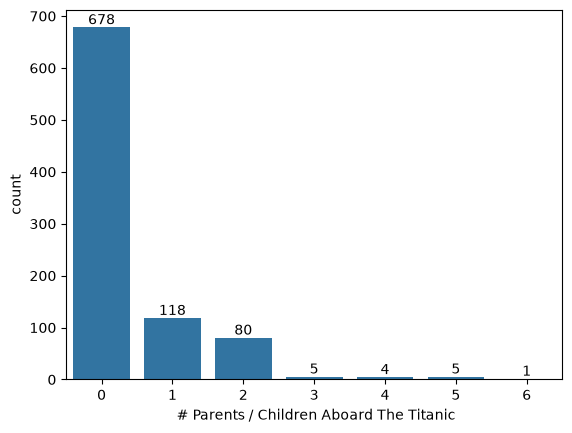

In [35]:
ax = sns.countplot(data=temp,x='Parch');
ax.bar_label(ax.containers[0]);
ax.set_xlabel(' # Parents / Children Aboard The Titanic');

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-13.png)

*为什么要做探索性数据分析？*

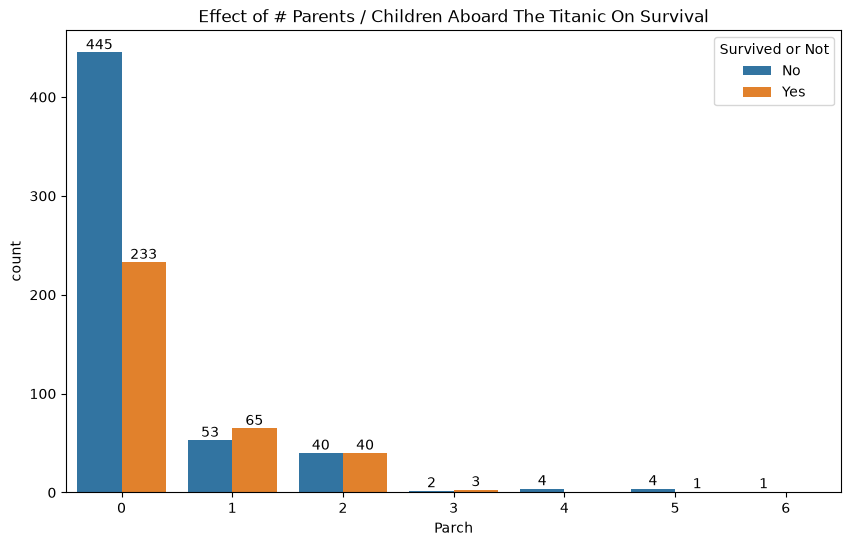

In [36]:
### Parch vs Survived
plt.figure(figsize=(10,6))
ax = sns.countplot(data=temp,x='Parch',hue='Survived');
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not', loc='upper right', labels=['No', 'Yes']);
plt.title('Effect of # Parents / Children Aboard The Titanic On Survival')
plt.show();

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-14.png)

*为什么要做探索性数据分析？*

In [37]:
temp['Family Size'] = temp['SibSp']+temp['Parch'] + 1

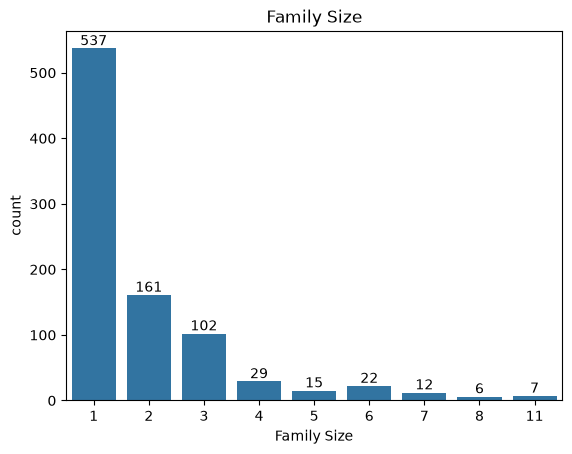

In [38]:
ax = sns.countplot(data=temp, x='Family Size')
ax.bar_label(ax.containers[0])
ax.set_title('Family Size');

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-15.png)

*为什么要做探索性数据分析？*

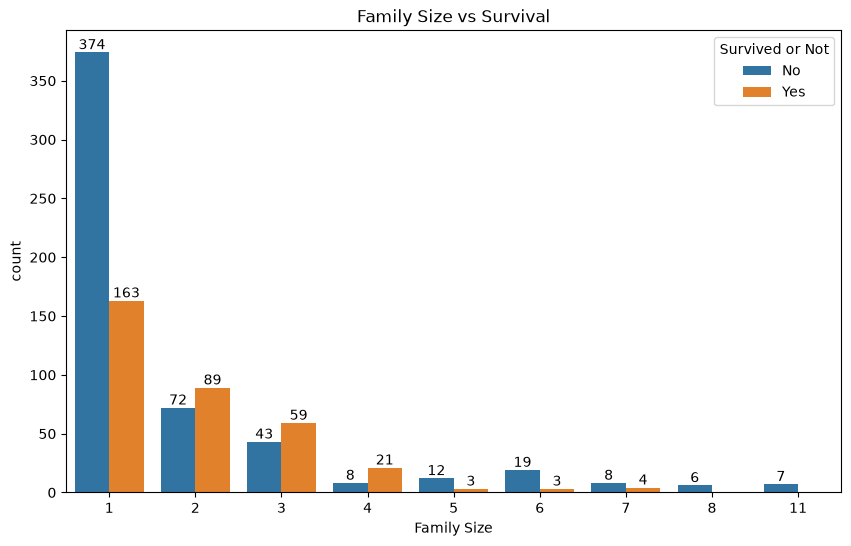

In [39]:
### Family Size vs Survived
plt.figure(figsize=(10,6))
ax = sns.countplot(data=temp,x='Family Size',hue='Survived');
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not', loc='upper right', labels=['No', 'Yes']);
plt.title('Family Size vs Survival')
plt.show();

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-16.png)

*为什么要做探索性数据分析？*

In [40]:
# Embarked 登船港口
temp.Embarked.unique()

array(['S', 'C', 'Q', nan], dtype=object)

**预期输出：**

```text
array(['S', 'C', 'Q', nan], dtype=object)
```

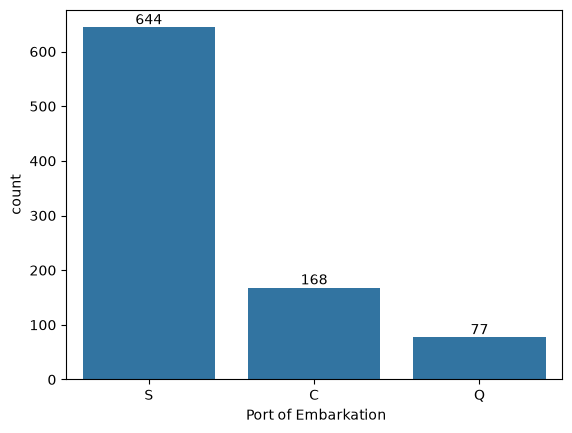

In [41]:
ax = sns.countplot(data=temp,x='Embarked');
ax.bar_label(ax.containers[0]);
ax.set_xlabel(' Port of Embarkation');

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-17.png)

*为什么要做探索性数据分析？*

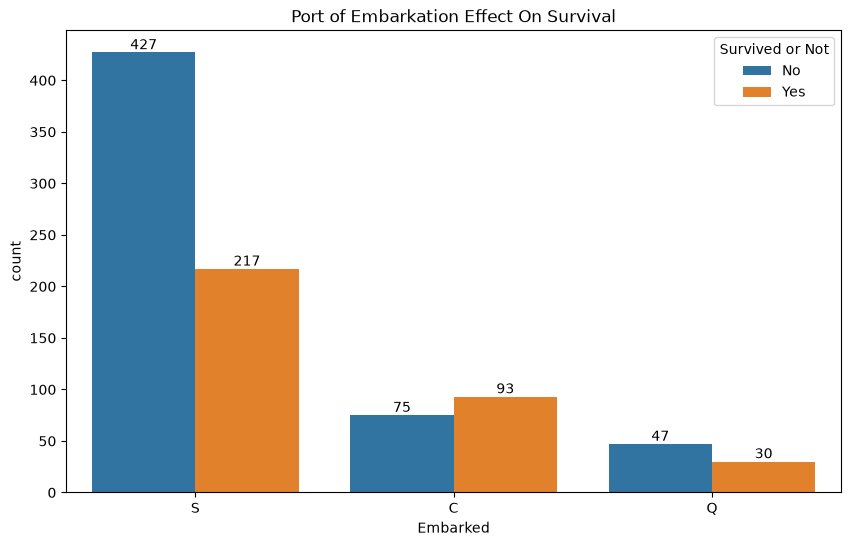

In [42]:
### Port of Embarkation vs Survived
plt.figure(figsize=(10,6))
ax = sns.countplot(data=temp,x='Embarked',hue='Survived');
ax.bar_label(ax.containers[0]);
ax.bar_label(ax.containers[1]);
plt.legend(title='Survived or Not', loc='upper right', labels=['No', 'Yes']);
plt.title('Port of Embarkation Effect On Survival')
plt.show();

**预期输出（图片）：**

![为什么要做探索性数据分析？](../assets/01_Titanic-Case-18.png)

*为什么要做探索性数据分析？*

In [43]:
# EDA结论
# EDA Analysis Results
# Based On The Dataset Only 40% People Were Able To Survived The Disaster.
# Mostly Childrens Are Being Rescued.
# People Above Age 20 had a chance of 35% of Being Survived From The Disaster.
# People Paid High Fare and Class Means VIPs Are Given Priority For Rescued.
# Out of Male and Females, Almost 75% Femals Survived The Disaster.
# People Traveling Alone or With A Smaller Family Size Upto 2 children had high chances of survival.
# Family Size Under 5 Had Higher Chance of Survival On Titanic Disaster.
# People Traveling Alone had approx 43% Chances of Survival.
# Family with Size 5+ Had Lesser Chance of Complete Survival On Titanic Disaster.
# 根据数据集，只有 40% 的人能够在灾难中幸存下来。
# 大多数儿童正在获救。
# 20 岁以上的人有 35% 的几率从灾难中幸存下来。
# 人们支付高票价和等级意味着 VIP 优先获救。
# 在男性和女性中，几乎 75% 的女性在灾难中幸存下来。
# 独自旅行或与多达 2 名儿童一起旅行的人有很高的生存机会。
# 5个成员以下的家庭在泰坦尼克号灾难中的生存几率更高。
# 独自旅行的人有大约 43% 的生存机会。
# 5个成员以上的家庭在泰坦尼克号灾难中完全生存的机会较小。

## 数据预处理

In [44]:
df_labeled = pd.read_csv ('titanic/LabeledData.csv')

In [45]:
def preprocess_data(data):
    # Let's Start By Dropping `PassengerID` `Name` `Ticket` `Cabin` 
    # 删除关联性不大的`PassengerID` `Name` `Ticket` `Cabin`列
    data = data.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)
    
    return data

In [46]:
df_labeled = preprocess_data(df_labeled)
df_labeled

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


**预期输出：**

```text
     Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0           0       3    male  22.0      1      0   7.2500        S
1           1       1  female  38.0      1      0  71.2833        C
2           1       3  female  26.0      0      0   7.9250        S
3           1       1  female  35.0      1      0  53.1000        S
4           0       3    male  35.0      0      0   8.0500        S
..        ...     ...     ...   ...    ...    ...      ...      ...
886         0       2    male  27.0      0      0  13.0000        S
887         1       1  female  19.0      0      0  30.0000        S
888         0       3  female   NaN      1      2  23.4500        S
889         1       1    male  26.0      0      0  30.0000        C
890         0       3    male  32.0      0      0   7.7500        Q

[891 rows x 8 columns]
```

In [47]:
# 统计每列缺失值的数量
missing_values = df_labeled.isnull().sum()

# 输出存在缺失值的列
print("存在缺失值的列：")
# print(missing_values[missing_values > 0])
print(missing_values)

存在缺失值的列：
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


**预期输出：**

```text
存在缺失值的列：
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64
```

In [48]:
# 删除Age为空的行
# 删除 'Age' 列为空的行,重新编排索引，并删除旧的索引列
df_labeled = df_labeled.dropna(subset=['Age']).reset_index(drop=True)

# 打印处理后的 DataFrame
print("\n删除 'age' 列为空的行后的 DataFrame:")

df_labeled


删除 'age' 列为空的行后的 DataFrame:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
709,0,3,female,39.0,0,5,29.1250,Q
710,0,2,male,27.0,0,0,13.0000,S
711,1,1,female,19.0,0,0,30.0000,S
712,1,1,male,26.0,0,0,30.0000,C


**预期输出：**

```text

删除 'age' 列为空的行后的 DataFrame:
     Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0           0       3    male  22.0      1      0   7.2500        S
1           1       1  female  38.0      1      0  71.2833        C
2           1       3  female  26.0      0      0   7.9250        S
3           1       1  female  35.0      1      0  53.1000        S
4           0       3    male  35.0      0      0   8.0500        S
..        ...     ...     ...   ...    ...    ...      ...      ...
709         0       3  female  39.0      0      5  29.1250        Q
710         0       2    male  27.0      0      0  13.0000        S
711         1       1  female  19.0      0      0  30.0000        S
712         1       1    male  26.0      0      0  30.0000        C
713         0       3    male  32.0      0      0   7.7500        Q

[714 rows x 8 columns]
```

In [49]:
# 找出存在缺失值的行
# missing_rows = df_labeled[df_labeled.isnull().any(axis=1)]
missing_rows = df_labeled[df_labeled['Embarked'].isnull()]
# 输出存在缺失值的行号
print("存在缺失值的行号：")
print(missing_rows.index)

存在缺失值的行号：
Index([46, 662], dtype='int64')


**预期输出：**

```text
存在缺失值的行号：
Index([46, 662], dtype='int64')
```

In [50]:
# 查看 Embarked 缺失值所在的行（避免硬编码索引）
df_labeled[df_labeled['Embarked'].isna()]


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
46,1,1,female,38.0,0,0,80.0,NaN
662,1,1,female,62.0,0,0,80.0,NaN


**预期输出：**

```text
     Survived  Pclass     Sex   Age  SibSp  Parch  Fare Embarked
46          1       1  female  38.0      0      0  80.0      NaN
662         1       1  female  62.0      0      0  80.0      NaN
```

In [51]:
# 删除Embarked为空的行
# 删除 'Embarked' 列为空的行,重新编排索引，并删除旧的索引列
df_labeled = df_labeled.dropna(subset=['Embarked']).reset_index(drop=True)

# 打印处理后的 DataFrame
print("\n删除 'Embarked' 列为空的行后的 DataFrame:")

df_labeled


删除 'Embarked' 列为空的行后的 DataFrame:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
707,0,3,female,39.0,0,5,29.1250,Q
708,0,2,male,27.0,0,0,13.0000,S
709,1,1,female,19.0,0,0,30.0000,S
710,1,1,male,26.0,0,0,30.0000,C


**预期输出：**

```text

删除 'Embarked' 列为空的行后的 DataFrame:
     Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0           0       3    male  22.0      1      0   7.2500        S
1           1       1  female  38.0      1      0  71.2833        C
2           1       3  female  26.0      0      0   7.9250        S
3           1       1  female  35.0      1      0  53.1000        S
4           0       3    male  35.0      0      0   8.0500        S
..        ...     ...     ...   ...    ...    ...      ...      ...
707         0       3  female  39.0      0      5  29.1250        Q
708         0       2    male  27.0      0      0  13.0000        S
709         1       1  female  19.0      0      0  30.0000        S
710         1       1    male  26.0      0      0  30.0000        C
711         0       3    male  32.0      0      0   7.7500        Q

[712 rows x 8 columns]
```

In [52]:
# from sklearn.impute import SimpleImputer

# # 创建SimpleImputer对象，在本例中使用均值填补缺失值
# # imputer = SimpleImputer(strategy='mean')

# # 创建SimpleImputer对象，在本例中使用众数填补缺失值
# imputer = SimpleImputer(strategy='most_frequent')

# # 使用SimpleImputer对象进行拟合和转换
# data_imputed = imputer.fit_transform(df_labeled)

# # 将填补后的数据转换回DataFrame
# df_labeled = pd.DataFrame(data_imputed, columns=df_labeled.columns)

# df_labeled

In [53]:
# 统计每列缺失值的数量
missing_values = df_labeled.isnull().sum()

# 输出存在缺失值的列
print("存在缺失值的列：")
# print(missing_values[missing_values > 0])
print(missing_values)

存在缺失值的列：
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


**预期输出：**

```text
存在缺失值的列：
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
```

In [54]:
df_labeled

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
707,0,3,female,39.0,0,5,29.1250,Q
708,0,2,male,27.0,0,0,13.0000,S
709,1,1,female,19.0,0,0,30.0000,S
710,1,1,male,26.0,0,0,30.0000,C


**预期输出：**

```text
     Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0           0       3    male  22.0      1      0   7.2500        S
1           1       1  female  38.0      1      0  71.2833        C
2           1       3  female  26.0      0      0   7.9250        S
3           1       1  female  35.0      1      0  53.1000        S
4           0       3    male  35.0      0      0   8.0500        S
..        ...     ...     ...   ...    ...    ...      ...      ...
707         0       3  female  39.0      0      5  29.1250        Q
708         0       2    male  27.0      0      0  13.0000        S
709         1       1  female  19.0      0      0  30.0000        S
710         1       1    male  26.0      0      0  30.0000        C
711         0       3    male  32.0      0      0   7.7500        Q

[712 rows x 8 columns]
```

In [55]:
# # 可以写成一个方法： 
# def preprocess_data(data):
#     # 删除关联性不大的`PassengerID` `Name` `Ticket` `Cabin`列
#     data = data.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)
#     # 删除存在空值的行
#     data.dropna(axis=0, inplace=True)
#     data.reset_index(drop=True)
#     return data

## 特征工程

### 特征分析

| 特征        | 类型     | 推荐处理方式                           |
| ----------- | -------- | -------------------------------------- |
| Pclass      | 有序分类 | 树模型保留整数；线性模型用 one-hot     |
| Sex         | 二分类   | 直接 0/1                               |
| Age         | 连续数值 | 保留原值（标准化）；可加“是否儿童”特征 |
| SibSp/Parch | 计数型   | 保留原值；加衍生特征 FamilySize        |
| Fare        | 连续数值 | log 变换 + 标准化                      |
| Embarked    | 无序分类 | one-hot 编码                           |

### 特征编码

In [56]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

def titanic_feature_engineering(df, onehot_pclass=False, scaler=None, is_train=True, age_median=None, fare_median=None):
    """
    Titanic 特征工程
    参数:
        df: 输入 DataFrame
        onehot_pclass: 是否对 Pclass 做 one-hot（默认 False）
        scaler: 已拟合的 StandardScaler（训练集返回，测试集复用）
        is_train: 是否训练集（决定是否 fit scaler）
        age_median: 训练集 Age 的中位数（测试集复用）
        fare_median: 训练集 Fare 的中位数（测试集复用）
    返回:
        df_new: 特征工程后的 DataFrame
        scaler: 训练好的 StandardScaler
        age_median: Age 中位数
        fare_median: Fare 中位数
    """
    df = df.copy()

    # ========== Sex（二分类 → 0/1） ==========
    df["Sex"] = df["Sex"].map({"male": 0, "female": 1}).astype(int)

    # ========== Embarked（无序分类 → one-hot） ==========
    df["Embarked"] = df["Embarked"].fillna("U")  # 缺失值补 "U"
    df = pd.get_dummies(df, columns=["Embarked"], prefix="Embarked")

    # ========== Pclass（有序分类） ==========
    if onehot_pclass:
        df = pd.get_dummies(df, columns=["Pclass"], prefix="Pclass")
    # 否则保留原始整数 1/2/3

    # ========== Age（连续数值 + 是否儿童） ==========
    if is_train:
        age_median = df["Age"].median()
    df["Age"] = df["Age"].fillna(age_median)
    df["IsChild"] = (df["Age"] < 16).astype(int)

    # ========== SibSp / Parch + FamilySize ==========
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    # ========== Fare（连续数值 → log + 标准化） ==========
    if is_train:
        fare_median = df["Fare"].median()
    df["Fare"] = df["Fare"].fillna(fare_median)
    df["Fare"] = df["Fare"].map(lambda x: np.log(x + 1))

    # ========== 删除无关字段 ==========
    drop_cols = ["PassengerId", "Name", "Ticket", "Cabin"]
    df = df.drop([c for c in drop_cols if c in df.columns], axis=1)

    # ========== 标准化数值特征 ==========
    num_features = ["Age", "Fare", "FamilySize"]
    if is_train:
        scaler = StandardScaler()
        df[num_features] = scaler.fit_transform(df[num_features])
    else:
        df[num_features] = scaler.transform(df[num_features])

    return df, scaler, age_median, fare_median


In [57]:
# 训练集特征工程
train_processed, scaler, age_median, fare_median = titanic_feature_engineering(
    df_labeled, onehot_pclass=False, is_train=True
)

# 测试集特征工程（复用训练集的 scaler 和 median）
test_processed, _, _, _ = titanic_feature_engineering(
    df_unLabeled, onehot_pclass=False, scaler=scaler, is_train=False,
    age_median=age_median, fare_median=fare_median
)


In [58]:
train_processed

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,IsChild,FamilySize
0,0,3,0,-0.527669,1,0,-0.976410,False,False,True,0,0.035965
1,1,1,1,0.577094,1,0,1.307189,True,False,False,0,0.035965
2,1,3,1,-0.251478,0,0,-0.893664,False,False,True,0,-0.637897
3,1,1,1,0.369951,1,0,1.002314,False,False,True,0,0.035965
4,0,3,0,0.369951,0,0,-0.879030,False,False,True,0,-0.637897
...,...,...,...,...,...,...,...,...,...,...,...,...
707,0,3,1,0.646142,0,5,0.386294,False,True,False,0,2.731412
708,0,2,0,-0.182430,0,0,-0.419978,False,False,True,0,-0.637897
709,1,1,1,-0.734812,0,0,0.416419,False,False,True,0,-0.637897
710,1,1,0,-0.251478,0,0,0.416419,True,False,False,0,-0.637897


**预期输出：**

```text
     Survived  Pclass  Sex       Age  SibSp  Parch      Fare  Embarked_C  \
0           0       3    0 -0.527669      1      0 -0.976410       False   
1           1       1    1  0.577094      1      0  1.307189        True   
2           1       3    1 -0.251478      0      0 -0.893664       False   
3           1       1    1  0.369951      1      0  1.002314       False   
4           0       3    0  0.369951      0      0 -0.879030       False   
..        ...     ...  ...       ...    ...    ...       ...         ...   
707         0       3    1  0.646142      0      5  0.386294       False   
708         0       2    0 -0.182430      0      0 -0.419978       False   
709         1       1    1 -0.734812      0      0  0.416419       False   
710         1       1    0 -0.251478      0      0  0.416419        True   
711         0       3    0  0.162808      0      0 -0.914500       False   

     Embarked_Q  Embarked_S  IsChild  FamilySize  
0         False        True        0    0.035965  
1         False       False        0    0.035965  
2         False        True        0   -0.637897  
3         False        True        0    0.035965  
4         False        True        0   -0.637897  
..          ...         ...      ...         ...  
707        True       False        0    2.731412  
708       False        True        0   -0.637897  
709       False        True        0   -0.637897  
710       False       False        0   -0.637897  
711        True       False        0   -0.637897  

[712 rows x 12 columns]
```

In [59]:
train_processed.to_csv('tmp.csv')

In [60]:
# X： 去除df_labeled的‘Survived’列
# Y： 保留df_labeled的‘Survived’列
X = train_processed.drop('Survived',axis=1)
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,IsChild,FamilySize
0,3,0,-0.527669,1,0,-0.976410,False,False,True,0,0.035965
1,1,1,0.577094,1,0,1.307189,True,False,False,0,0.035965
2,3,1,-0.251478,0,0,-0.893664,False,False,True,0,-0.637897
3,1,1,0.369951,1,0,1.002314,False,False,True,0,0.035965
4,3,0,0.369951,0,0,-0.879030,False,False,True,0,-0.637897
...,...,...,...,...,...,...,...,...,...,...,...
707,3,1,0.646142,0,5,0.386294,False,True,False,0,2.731412
708,2,0,-0.182430,0,0,-0.419978,False,False,True,0,-0.637897
709,1,1,-0.734812,0,0,0.416419,False,False,True,0,-0.637897
710,1,0,-0.251478,0,0,0.416419,True,False,False,0,-0.637897


**预期输出：**

```text
     Pclass  Sex       Age  SibSp  Parch      Fare  Embarked_C  Embarked_Q  \
0         3    0 -0.527669      1      0 -0.976410       False       False   
1         1    1  0.577094      1      0  1.307189        True       False   
2         3    1 -0.251478      0      0 -0.893664       False       False   
3         1    1  0.369951      1      0  1.002314       False       False   
4         3    0  0.369951      0      0 -0.879030       False       False   
..      ...  ...       ...    ...    ...       ...         ...         ...   
707       3    1  0.646142      0      5  0.386294       False        True   
708       2    0 -0.182430      0      0 -0.419978       False       False   
709       1    1 -0.734812      0      0  0.416419       False       False   
710       1    0 -0.251478      0      0  0.416419        True       False   
711       3    0  0.162808      0      0 -0.914500       False        True   

     Embarked_S  IsChild  FamilySize  
0          True        0    0.035965  
1         False        0    0.035965  
2          True        0   -0.637897  
3          True        0    0.035965  
4          True        0   -0.637897  
..          ...      ...         ...  
707       False        0    2.731412  
708        True        0   -0.637897  
709        True        0   -0.637897  
710       False        0   -0.637897  
711       False        0   -0.637897  

[712 rows x 11 columns]
```

In [61]:
y = train_processed['Survived']
y

0      0
1      1
2      1
3      1
4      0
      ..
707    0
708    0
709    1
710    1
711    0
Name: Survived, Length: 712, dtype: int64

**预期输出：**

```text
0      0
1      1
2      1
3      1
4      0
      ..
707    0
708    0
709    1
710    1
711    0
Name: Survived, Length: 712, dtype: int64
```

### 特征选择

#### 计算DataFrame 中所有列的成对相关性系数观察特征之间的相关性

In [62]:
X.corr() # Pandas dataframe.corr()用于查找数据帧中所有列的成对相关性。任何na值会自动排除。对于 DataFrame 中的任何非数字数据类型列，将忽略该列。

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,IsChild,FamilySize
Pclass,1.000000,-0.150826,-0.365902,0.065187,0.023666,-0.715698,-0.279194,0.131989,0.197831,0.167817,0.054467
Sex,-0.150826,1.000000,-0.099037,0.106296,0.249543,0.264902,0.103611,0.027256,-0.109078,0.116516,0.210154
Age,-0.365902,-0.099037,1.000000,-0.307351,-0.187896,0.111644,0.038268,-0.021693,-0.025431,-0.583723,-0.300699
SibSp,0.065187,0.106296,-0.307351,1.000000,0.383338,0.302069,-0.046227,0.051331,0.018968,0.476860,0.847212
Parch,0.023666,0.249543,-0.187896,0.383338,1.000000,0.325265,-0.009523,-0.009417,0.013259,0.354275,0.815440
Fare,-0.715698,0.264902,0.111644,0.302069,0.325265,1.000000,0.305915,-0.087883,-0.243305,0.086489,0.376403
Embarked_C,-0.279194,0.103611,0.038268,-0.046227,-0.009523,0.305915,1.000000,-0.095623,-0.884986,0.032236,-0.034449
Embarked_Q,0.131989,0.027256,-0.021693,0.051331,-0.009417,-0.087883,-0.095623,1.000000,-0.378859,0.039088,0.026754
Embarked_S,0.197831,-0.109078,-0.025431,0.018968,0.013259,-0.243305,-0.884986,-0.378859,1.000000,-0.048254,0.019514
IsChild,0.167817,0.116516,-0.583723,0.476860,0.354275,0.086489,0.032236,0.039088,-0.048254,1.000000,0.502634


**预期输出：**

```text
              Pclass       Sex       Age     SibSp     Parch      Fare  \
Pclass      1.000000 -0.150826 -0.365902  0.065187  0.023666 -0.715698   
Sex        -0.150826  1.000000 -0.099037  0.106296  0.249543  0.264902   
Age        -0.365902 -0.099037  1.000000 -0.307351 -0.187896  0.111644   
SibSp       0.065187  0.106296 -0.307351  1.000000  0.383338  0.302069   
Parch       0.023666  0.249543 -0.187896  0.383338  1.000000  0.325265   
Fare       -0.715698  0.264902  0.111644  0.302069  0.325265  1.000000   
Embarked_C -0.279194  0.103611  0.038268 -0.046227 -0.009523  0.305915   
Embarked_Q  0.131989  0.027256 -0.021693  0.051331 -0.009417 -0.087883   
Embarked_S  0.197831 -0.109078 -0.025431  0.018968  0.013259 -0.243305   
IsChild     0.167817  0.116516 -0.583723  0.476860  0.354275  0.086489   
FamilySize  0.054467  0.210154 -0.300699  0.847212  0.815440  0.376403   

            Embarked_C  Embarked_Q  Embarked_S   IsChild  FamilySize  
Pclass       -0.279194    0.131989    0.197831  0.167817    0.054467  
Sex           0.103611    0.027256   -0.109078  0.116516    0.210154  
Age           0.038268   -0.021693   -0.025431 -0.583723   -0.300699  
SibSp        -0.046227    0.051331    0.018968  0.476860    0.847212  
Parch        -0.009523   -0.009417    0.013259  0.354275    0.815440  
Fare          0.305915   -0.087883   -0.243305  0.086489    0.376403  
Embarked_C    1.000000   -0.095623   -0.884986  0.032236   -0.034449  
Embarked_Q   -0.095623    1.000000   -0.378859  0.039088    0.026754  
Embarked_S   -0.884986   -0.378859    1.000000 -0.048254    0.019514  
IsChild       0.032236    0.039088   -0.048254  1.000000    0.502634  
FamilySize   -0.034449    0.026754    0.019514  0.502634    1.000000
```

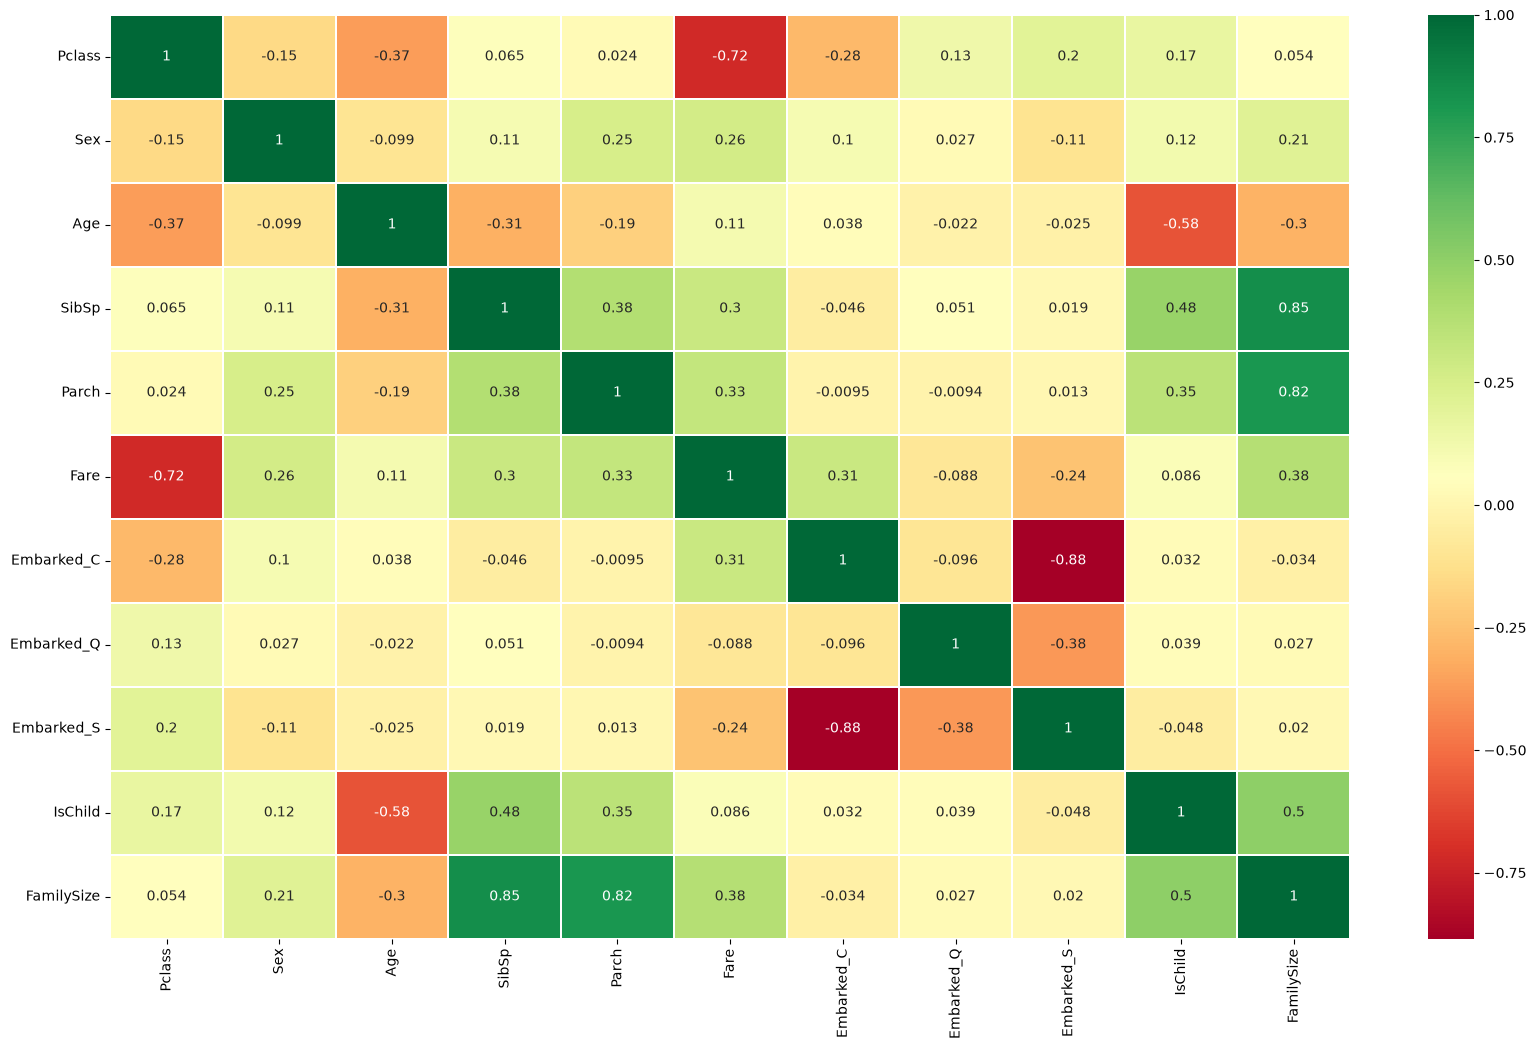

In [63]:
sns.heatmap(X.corr(),annot=True,cmap='RdYlGn',linewidths=0.2)
fig=plt.gcf()
fig.set_size_inches(20,12)
plt.show()

**预期输出（图片）：**

![计算DataFrame 中所有列的成对相关性系数观察特征之间的相关性](../assets/01_Titanic-Case-19.png)

*计算DataFrame 中所有列的成对相关性系数观察特征之间的相关性*

In [64]:
# 在热图结果中：
# 正相关：如果 A 的增加导致特征 B 的增加，那么这两个特征是正相关的。 完全正相关特征的值为 1。
# 负相关：如果 A 的增加导致特征 B 的减少，那么这两个特征是负相关的。 那么完全负相关特征的值为-1。
# 在我们的训练数据中有两个高度或完全相关的特征会导致多重共线性，因此最好将它们删除。

# 在上述热图中，我们可以看到没有高度相关的特征。 在特征 Parch 和 SibSp 之间，相关性的最高值为 0.41。 因此无需删除任何功能。

In [65]:
# 如果上述方式还不够明显，我们也可以在代码的帮助下通过定义像 0.6 这样的阈值来做到这一点
threshold=0.6
# find and remove correlated features
def correlation(dataset, threshold):
    col_corr = set()  # Set of all the names of correlated columns
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold: # we are interested in absolute coeff value
                colname = corr_matrix.columns[i]  # getting the name of column
                col_corr.add(colname)
    return col_corr

correlation(X,threshold)
# 如果输出的结果为set(),意味着没有高相关的特征，不需要去删除特征


{'Embarked_S', 'FamilySize', 'Fare'}

**预期输出：**

```text
{'Embarked_S', 'FamilySize', 'Fare'}
```

#### sklearn提供的方法进行特征选择

sklean提供了一些特征选择的方法，比如说VarianceThreshold

In [66]:
# ===============================
# 方差特征选择
# ===============================
from sklearn.feature_selection import VarianceThreshold
# selector = VarianceThreshold(threshold=0.01)  # 去掉低方差特征
selector = VarianceThreshold(threshold=0.1)  # 去掉低方差特征
X_sel = selector.fit_transform(X)

# 保留特征列名
selected_cols = X.columns[selector.get_support()]
X_sel = pd.DataFrame(X_sel, columns=selected_cols)

X = X_sel

X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_S,IsChild,FamilySize
0,3.0,0.0,-0.527669,1.0,0.0,-0.976410,0.0,1.0,0.0,0.035965
1,1.0,1.0,0.577094,1.0,0.0,1.307189,1.0,0.0,0.0,0.035965
2,3.0,1.0,-0.251478,0.0,0.0,-0.893664,0.0,1.0,0.0,-0.637897
3,1.0,1.0,0.369951,1.0,0.0,1.002314,0.0,1.0,0.0,0.035965
4,3.0,0.0,0.369951,0.0,0.0,-0.879030,0.0,1.0,0.0,-0.637897
...,...,...,...,...,...,...,...,...,...,...
707,3.0,1.0,0.646142,0.0,5.0,0.386294,0.0,0.0,0.0,2.731412
708,2.0,0.0,-0.182430,0.0,0.0,-0.419978,0.0,1.0,0.0,-0.637897
709,1.0,1.0,-0.734812,0.0,0.0,0.416419,0.0,1.0,0.0,-0.637897
710,1.0,0.0,-0.251478,0.0,0.0,0.416419,1.0,0.0,0.0,-0.637897


**预期输出：**

```text
     Pclass  Sex       Age  SibSp  Parch      Fare  Embarked_C  Embarked_S  \
0       3.0  0.0 -0.527669    1.0    0.0 -0.976410         0.0         1.0   
1       1.0  1.0  0.577094    1.0    0.0  1.307189         1.0         0.0   
2       3.0  1.0 -0.251478    0.0    0.0 -0.893664         0.0         1.0   
3       1.0  1.0  0.369951    1.0    0.0  1.002314         0.0         1.0   
4       3.0  0.0  0.369951    0.0    0.0 -0.879030         0.0         1.0   
..      ...  ...       ...    ...    ...       ...         ...         ...   
707     3.0  1.0  0.646142    0.0    5.0  0.386294         0.0         0.0   
708     2.0  0.0 -0.182430    0.0    0.0 -0.419978         0.0         1.0   
709     1.0  1.0 -0.734812    0.0    0.0  0.416419         0.0         1.0   
710     1.0  0.0 -0.251478    0.0    0.0  0.416419         1.0         0.0   
711     3.0  0.0  0.162808    0.0    0.0 -0.914500         0.0         0.0   

     IsChild  FamilySize  
0        0.0    0.035965  
1        0.0    0.035965  
2        0.0   -0.637897  
3        0.0    0.035965  
4        0.0   -0.637897  
..       ...         ...  
707      0.0    2.731412  
708      0.0   -0.637897  
709      0.0   -0.637897  
710      0.0   -0.637897  
711      0.0   -0.637897  

[712 rows x 10 columns]
```

In [67]:
# from sklearn.feature_selection import VarianceThreshold
# import numpy as np

# # 创建示例数据集
# # X = np.array([[0, 2, 0, 3],
# #               [0, 1, 4, 3],
# #               [0, 1, 1, 3],
# #               [0, 1, 0, 3]])

# # columns = X.columns

# # 创建 VarianceThreshold 对象，设置方差阈值为0.1
# selector = VarianceThreshold(threshold=0.1)

# # dataframe转np.array

# # X = X.values

# # 进行特征选择
# X_selected = selector.fit_transform(X)

# # 将选择后的特征矩阵转换为 DataFrame
# # X_selected_df = pd.DataFrame(X_selected, columns=columns[selector.get_support()])

# # 设置 Pandas 显示选项，确保所有列都会显示
# # pd.set_option('display.max_columns', None)

# X = X_selected
# # 查看选择后的特征矩阵
# print(X)

# 模型训练

In [68]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

"""
test_size:test样本的占比
random_state: 可以为整数、RandomState实例或None，默认为None
①若为None时，每次生成的数据都是随机，可能不一样
②若为整数时，每次生成的数据都相同
"""

'\ntest_size:test样本的占比\nrandom_state: 可以为整数、RandomState实例或None，默认为None\n①若为None时，每次生成的数据都是随机，可能不一样\n②若为整数时，每次生成的数据都相同\n'

**预期输出：**

```text
'\ntest_size:test样本的占比\nrandom_state: 可以为整数、RandomState实例或None，默认为None\n①若为None时，每次生成的数据都是随机，可能不一样\n②若为整数时，每次生成的数据都相同\n'
```

In [69]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_S,IsChild,FamilySize
43,2.0,1.0,-1.701479,1.0,2.0,0.337139,0.0,1.0,1.0,1.383688
42,3.0,0.0,-0.078859,0.0,0.0,-0.979066,1.0,0.0,0.0,-0.637897
73,1.0,0.0,2.855666,0.0,0.0,0.563596,1.0,0.0,0.0,-0.637897
167,3.0,0.0,-0.389573,0.0,0.0,-1.002231,0.0,1.0,0.0,-0.637897
449,3.0,0.0,0.162808,0.0,0.0,-0.902044,0.0,1.0,0.0,-0.637897
...,...,...,...,...,...,...,...,...,...,...
71,3.0,0.0,-0.251478,1.0,2.0,0.035060,0.0,1.0,0.0,1.383688
106,2.0,0.0,-0.458621,0.0,0.0,-0.276474,1.0,0.0,0.0,-0.637897
270,3.0,0.0,1.060427,0.0,0.0,-0.879030,0.0,1.0,0.0,-0.637897
435,2.0,0.0,-1.494336,1.0,1.0,0.623694,0.0,1.0,1.0,0.709826


**预期输出：**

```text
     Pclass  Sex       Age  SibSp  Parch      Fare  Embarked_C  Embarked_S  \
43      2.0  1.0 -1.701479    1.0    2.0  0.337139         0.0         1.0   
42      3.0  0.0 -0.078859    0.0    0.0 -0.979066         1.0         0.0   
73      1.0  0.0  2.855666    0.0    0.0  0.563596         1.0         0.0   
167     3.0  0.0 -0.389573    0.0    0.0 -1.002231         0.0         1.0   
449     3.0  0.0  0.162808    0.0    0.0 -0.902044         0.0         1.0   
..      ...  ...       ...    ...    ...       ...         ...         ...   
71      3.0  0.0 -0.251478    1.0    2.0  0.035060         0.0         1.0   
106     2.0  0.0 -0.458621    0.0    0.0 -0.276474         1.0         0.0   
270     3.0  0.0  1.060427    0.0    0.0 -0.879030         0.0         1.0   
435     2.0  0.0 -1.494336    1.0    1.0  0.623694         0.0         1.0   
102     3.0  0.0 -0.665764    0.0    0.0 -1.002231         0.0         1.0   

     IsChild  FamilySize  
43       1.0    1.383688  
42       0.0   -0.637897  
73       0.0   -0.637897  
167      0.0   -0.637897  
449      0.0   -0.637897  
..       ...         ...  
71       0.0    1.383688  
106      0.0   -0.637897  
270      0.0   -0.637897  
435      1.0    0.709826  
102      0.0   -0.637897  

[498 rows x 10 columns]
```

In [70]:
y_train

43     1
42     0
73     0
167    0
449    1
      ..
71     0
106    0
270    1
435    1
102    0
Name: Survived, Length: 498, dtype: int64

**预期输出：**

```text
43     1
42     0
73     0
167    0
449    1
      ..
71     0
106    0
270    1
435    1
102    0
Name: Survived, Length: 498, dtype: int64
```

In [71]:
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict ## Cross Validation

## 朴素贝叶斯Naive Bayes

--------GaussianNB Naive Bayes -------
The accuracy Gaussian Naive Bayes Classifier is 77.1
[[95 27]
 [22 70]]


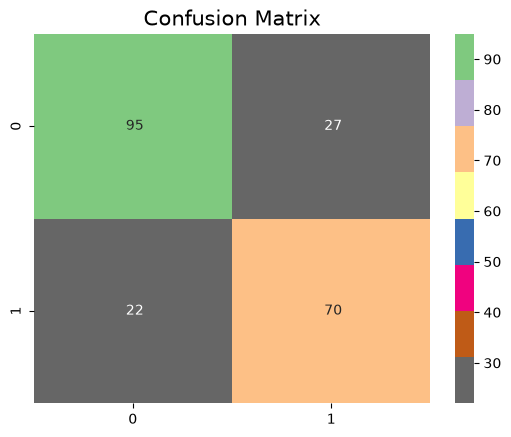

In [72]:
#################################### Naive Bayes ########################
# 调用朴素贝叶斯算法进行预测
from sklearn.naive_bayes import GaussianNB
g_model= GaussianNB()
g_model.fit(X_train,y_train)
prediction_gnb=g_model.predict(X_test)

print('--------GaussianNB Naive Bayes -------')
print('The accuracy Gaussian Naive Bayes Classifier is',round(accuracy_score(y_test, prediction_gnb)*100,2)) # metrics.accuracy_score进行准确率衡量

sns.heatmap(confusion_matrix(y_test,prediction_gnb),annot=True,fmt='3.0f',cmap="Accent_r") # heatmap显示混淆矩阵
print(confusion_matrix(y_test,prediction_gnb))

plt.title('Confusion Matrix', y=1, size=15);


**预期输出：**

```text
--------GaussianNB Naive Bayes -------
The accuracy Gaussian Naive Bayes Classifier is 77.1
[[95 27]
 [22 70]]
```

**预期输出（图片）：**

![朴素贝叶斯Naive Bayes](../assets/01_Titanic-Case-20.png)

*朴素贝叶斯Naive Bayes*

The cross validated score for Gaussian Naive Bayes classifier is: 78.53
[[347  77]
 [ 76 212]]


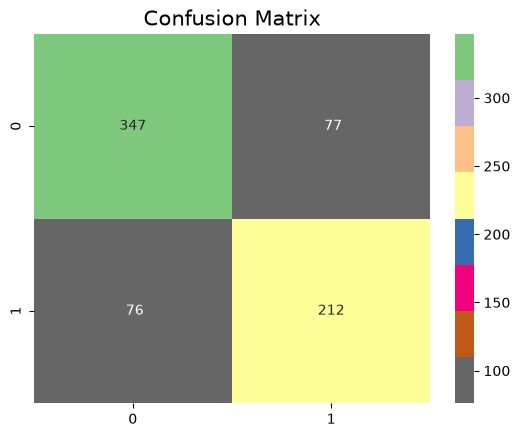

In [73]:
# K折交叉验证,得到更准缺的结果
kfold = KFold(n_splits=10,shuffle=True,random_state=42) # split the data into 10 equal parts，这不是只是帮助理解K折交叉验证的原理，可删除
# for train, test in kfold.split(X):
#     print(train,test)
#     print("--------")
#     print(np.array(X)[train], np.array(X)[test])
#     print("*"*50)

from sklearn.naive_bayes import GaussianNB
g_model= GaussianNB()

result_gnb=cross_val_score(g_model,X,y,cv=10,scoring='accuracy')  # cv=10 表示10折

print('The cross validated score for Gaussian Naive Bayes classifier is:',round(result_gnb.mean()*100,2))

y_pred = cross_val_predict(g_model,X,y,cv=10)  

sns.heatmap(confusion_matrix(y,y_pred),annot=True,fmt='3.0f',cmap="Accent_r") # heatmap显示混淆矩阵
print(confusion_matrix(y,y_pred))

plt.title('Confusion Matrix', y=1, size=15);

**预期输出：**

```text
The cross validated score for Gaussian Naive Bayes classifier is: 78.53
[[347  77]
 [ 76 212]]
```

**预期输出（图片）：**

![朴素贝叶斯Naive Bayes](../assets/01_Titanic-Case-21.png)

*朴素贝叶斯Naive Bayes*

## 支持向量机SVM

--------SVM -------
The accuracy SVM is 81.78


The cross validated score for SVM is: 81.46


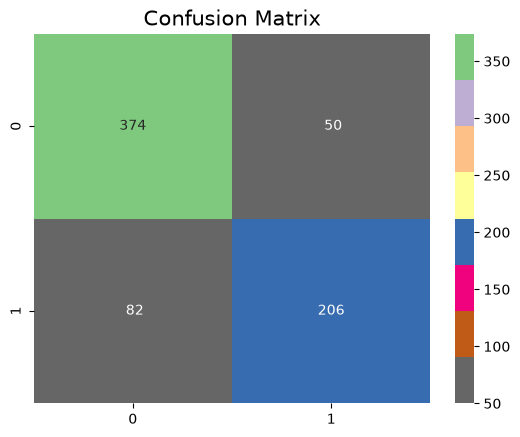

In [74]:
#################################### SVM ########################
from sklearn.svm import SVC
s_model = SVC()
s_model.fit(X_train,y_train)
prediction_svm=s_model.predict(X_test)

print('--------SVM -------')
print('The accuracy SVM is',round(accuracy_score(y_test, prediction_svm)*100,2))

result_svm=cross_val_score(s_model,X,y,cv=10,scoring='accuracy')

print('The cross validated score for SVM is:',round(result_svm.mean()*100,2))

y_pred = cross_val_predict(s_model,X,y,cv=10)
sns.heatmap(confusion_matrix(y,y_pred),annot=True,fmt='3.0f',cmap="Accent_r")
plt.title('Confusion Matrix', y=1, size=15);


**预期输出：**

```text
--------SVM -------
The accuracy SVM is 81.78
The cross validated score for SVM is: 81.46
```

**预期输出（图片）：**

![支持向量机SVM](../assets/01_Titanic-Case-22.png)

*支持向量机SVM*

## K近邻分类器KNN

--------KNN -------
The accuracy KNN Classifier is 76.64


The cross validated score for KNN classifier is: 80.63


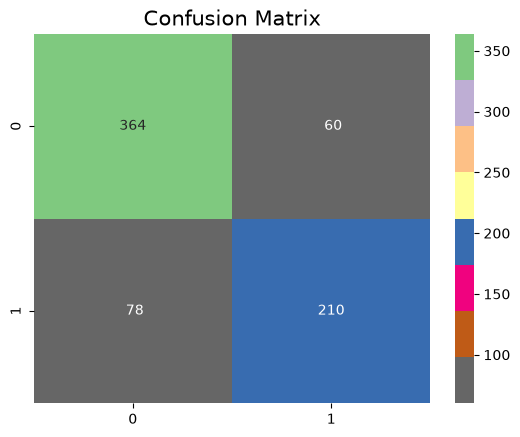

In [75]:
#################################### KNN ########################
from sklearn.neighbors import KNeighborsClassifier
k_model =  KNeighborsClassifier()
k_model.fit(X_train,y_train)
prediction_knn=k_model.predict(X_test)

print('--------KNN -------')
print('The accuracy KNN Classifier is',round(accuracy_score(y_test, prediction_knn)*100,2))

kfold = KFold(n_splits=10,shuffle=True, random_state=42)

result_knn=cross_val_score(k_model,X,y,cv=10,scoring='accuracy')

print('The cross validated score for KNN classifier is:',round(result_knn.mean()*100,2))

y_pred = cross_val_predict(k_model,X,y,cv=10)
sns.heatmap(confusion_matrix(y,y_pred),annot=True,fmt='3.0f',cmap="Accent_r")
plt.title('Confusion Matrix', y=1, size=15);


**预期输出：**

```text
--------KNN -------
The accuracy KNN Classifier is 76.64
The cross validated score for KNN classifier is: 80.63
```

**预期输出（图片）：**

![K近邻分类器KNN](../assets/01_Titanic-Case-23.png)

*K近邻分类器KNN*

## 逻辑回归Logistic Regression

--------Logistic Regression -------
The accuracy Logistic Regression is 80.84
The cross validated score for Logistic Regression is: 80.48


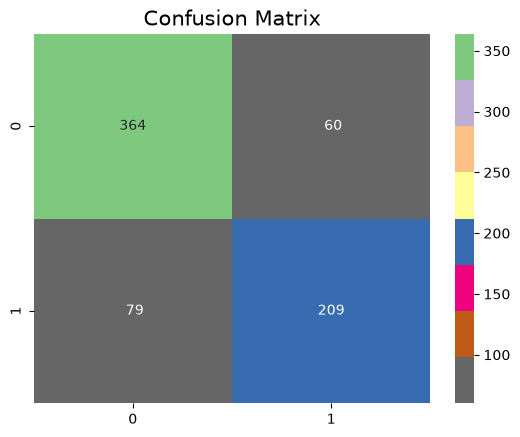

In [76]:
#################################### Logistic Regression ########################
from sklearn.linear_model import LogisticRegression
l_model =  LogisticRegression(penalty='l2', C=1.0, solver='lbfgs')
l_model.fit(X_train,y_train)
prediction_lr=l_model.predict(X_test)

print('--------Logistic Regression -------')
print('The accuracy Logistic Regression is',round(accuracy_score(y_test, prediction_lr)*100,2))

result_lr=cross_val_score(l_model,X,y,cv=10,scoring='accuracy')

print('The cross validated score for Logistic Regression is:',round(result_lr.mean()*100,2))

y_pred = cross_val_predict(l_model,X,y,cv=10)
sns.heatmap(confusion_matrix(y,y_pred),annot=True,fmt='3.0f',cmap="Accent_r")
plt.title('Confusion Matrix', y=1, size=15);


**预期输出：**

```text
--------Logistic Regression -------
The accuracy Logistic Regression is 80.84
The cross validated score for Logistic Regression is: 80.48
```

**预期输出（图片）：**

![逻辑回归Logistic Regression](../assets/01_Titanic-Case-24.png)

*逻辑回归Logistic Regression*

## 随机森林 Random Forest

--------Random Forest Classifier -------
The accuracy Random Forest Classifier  is 78.04
OOB Score: 81.12


The cross validated score for Random Forest Classifier is: 80.92


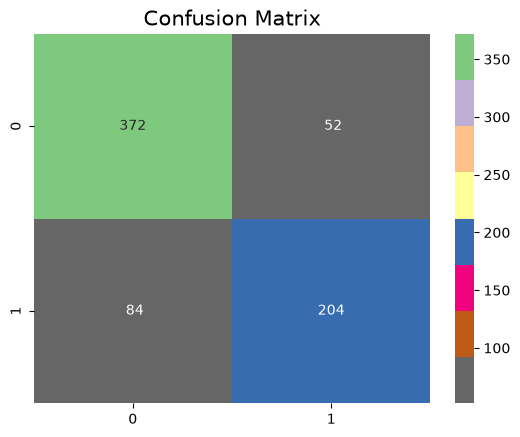

In [77]:
# Random Forests
from sklearn.ensemble import RandomForestClassifier
r_model = RandomForestClassifier(n_estimators=800,
                             min_samples_split=5,
                             max_features='sqrt',
                             oob_score=True,
                             random_state=42, n_jobs=-1)

r_model.fit(X_train,y_train)
prediction_rf=r_model.predict(X_test)

print('--------Random Forest Classifier -------')
print('The accuracy Random Forest Classifier  is',round(accuracy_score(y_test, prediction_rf)*100,2))
print('OOB Score:', round(r_model.oob_score_*100, 2))

result_rf=cross_val_score(r_model,X,y,cv=10,scoring='accuracy')

print('The cross validated score for Random Forest Classifier is:',round(result_rf.mean()*100,2))

y_pred = cross_val_predict(r_model,X,y,cv=10)
sns.heatmap(confusion_matrix(y,y_pred),annot=True,fmt='3.0f',cmap="Accent_r")
plt.title('Confusion Matrix', y=1, size=15);


**预期输出：**

```text
--------Random Forest Classifier -------
The accuracy Random Forest Classifier  is 78.04
OOB Score: 81.12
The cross validated score for Random Forest Classifier is: 80.92
```

**预期输出（图片）：**

![随机森林 Random Forest](../assets/01_Titanic-Case-25.png)

*随机森林 Random Forest*

## 自适应提升ADA Boost

--------ADA Boost -------
The accuracy ADA Boost Classifier is 76.17


The cross validated score for ADA Boost classifier is: 80.9


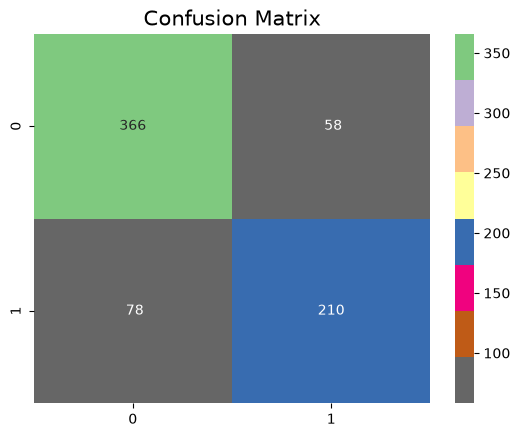

In [78]:
from sklearn.ensemble import AdaBoostClassifier
a_model= AdaBoostClassifier()

a_model.fit(X_train,y_train)
prediction_ada=a_model.predict(X_test)

print('--------ADA Boost -------')
print('The accuracy ADA Boost Classifier is',round(accuracy_score(y_test, prediction_ada)*100,2))

result_ada=cross_val_score(a_model,X,y,cv=10,scoring='accuracy')

print('The cross validated score for ADA Boost classifier is:',round(result_ada.mean()*100,2))

y_pred = cross_val_predict(a_model,X,y,cv=10)
sns.heatmap(confusion_matrix(y,y_pred),annot=True,fmt='3.0f',cmap="Accent_r")
plt.title('Confusion Matrix', y=1, size=15);


**预期输出：**

```text
--------ADA Boost -------
The accuracy ADA Boost Classifier is 76.17
The cross validated score for ADA Boost classifier is: 80.9
```

**预期输出（图片）：**

![自适应提升ADA Boost](../assets/01_Titanic-Case-26.png)

*自适应提升ADA Boost*

## 以上几种算法模型的评估对比

In [79]:
models = pd.DataFrame({
    'Model': ['Support Vector Machines', 'KNN', 'Logistic Regression', 
              'Random Forest', 'Naive Bayes', 'AdaBoostClassifier'],
    'Score': [result_svm.mean(), result_knn.mean(), result_lr.mean(), 
              result_rf.mean(), result_gnb.mean(), result_ada.mean()]})
models.sort_values(by='Score',ascending=False)

,Model,Score
0,Support Vector Machines,0.814613
3,Random Forest,0.809174
5,AdaBoostClassifier,0.809038
1,KNN,0.806318
2,Logistic Regression,0.804832
4,Naive Bayes,0.785290


**预期输出：**

```text
                     Model     Score
0  Support Vector Machines  0.814613
3            Random Forest  0.809174
5       AdaBoostClassifier  0.809038
1                      KNN  0.806318
2      Logistic Regression  0.804832
4              Naive Bayes  0.785290
```

## 使用模型进行预测

In [80]:
test_processed

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,IsChild,FamilySize
0,3,0,0.335427,0,0,-0.905019,False,True,False,0,-0.637897
1,3,1,1.198523,1,0,-1.008787,False,False,True,0,0.035965
2,2,0,2.234238,0,0,-0.704045,False,True,False,0,-0.637897
3,3,0,-0.182430,0,0,-0.810126,False,False,True,0,-0.637897
4,3,1,-0.527669,1,1,-0.474937,False,False,True,0,0.709826
...,...,...,...,...,...,...,...,...,...,...,...
409,3,0,-0.113383,0,0,-0.879030,False,False,True,0,-0.637897
410,1,1,0.646142,0,0,1.748022,True,False,False,0,-0.637897
411,3,0,0.611618,0,0,-0.976410,False,False,True,0,-0.637897
412,3,0,-0.113383,0,0,-0.879030,False,False,True,0,-0.637897


**预期输出：**

```text
     Pclass  Sex       Age  SibSp  Parch      Fare  Embarked_C  Embarked_Q  \
0         3    0  0.335427      0      0 -0.905019       False        True   
1         3    1  1.198523      1      0 -1.008787       False       False   
2         2    0  2.234238      0      0 -0.704045       False        True   
3         3    0 -0.182430      0      0 -0.810126       False       False   
4         3    1 -0.527669      1      1 -0.474937       False       False   
..      ...  ...       ...    ...    ...       ...         ...         ...   
409       3    0 -0.113383      0      0 -0.879030       False       False   
410       1    1  0.646142      0      0  1.748022        True       False   
411       3    0  0.611618      0      0 -0.976410       False       False   
412       3    0 -0.113383      0      0 -0.879030       False       False   
413       3    0 -0.113383      1      1  0.118620        True       False   

     Embarked_S  IsChild  FamilySize  
0         False        0   -0.637897  
1          True        0    0.035965  
2         False        0   -0.637897  
3          True        0   -0.637897  
4          True        0    0.709826  
..          ...      ...         ...  
409        True        0   -0.637897  
410       False        0   -0.637897  
411        True        0   -0.637897  
412        True        0   -0.637897  
413       False        0    0.709826  

[414 rows x 11 columns]
```

In [81]:
# ===============================
# 未标注数据预测
# ===============================
# 读取未标注数据
df_unLabeled_data = pd.read_csv('titanic/UnlabeledData.csv')

# 特征工程（复用训练集的 scaler 和 median）
test_processed, _, _, _ = titanic_feature_engineering(
    df_unLabeled_data, onehot_pclass=False, scaler=scaler, is_train=False,
    age_median=age_median, fare_median=fare_median
)

# 保持与训练集特征列一致（注意：X 可能已经过 VarianceThreshold 处理，要用 X.columns 而不是 train_processed.columns）
train_feature_cols = list(X.columns)
test_processed = test_processed[train_feature_cols]

# 预测
y_pred_unlabeled = r_model.predict(test_processed)
print("Predictions on unlabeled data:", y_pred_unlabeled)


Predictions on unlabeled data: [0 0 0 1 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 1 0 1 0 1
 0 0 0 0 1 0 1 1 0 1 0 1 1 1 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0 0 1
 1 0 0 1 0 1 1 0 1 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0
 0 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0
 1 0 1 0 0 1 0 0 1 0 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1
 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 1 0 1 0 1 0 0 1 0 0 0 0 1 1 0 1 0 1 0 1 0 1
 0 1 1 0 1 0 0 0 1 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 0 1
 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 0 1 1 1 1 0 0 1 0 0 1 0 0
 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 1 1
 1 0 0 1 0 0 0]


**预期输出：**

```text
Predictions on unlabeled data: [0 0 0 1 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 1 0 1 0 1
 0 0 0 0 1 0 1 1 0 1 0 1 1 1 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0 0 1
 1 0 0 1 0 1 1 0 1 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0
 0 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0
 1 0 1 0 0 1 0 0 1 0 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1
 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 1 0 1 0 1 0 0 1 0 0 0 0 1 1 0 1 0 1 0 1 0 1
 0 1 1 0 1 0 0 0 1 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 0 1
 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 0 1 1 1 1 0 0 1 0 0 1 0 0
 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 1 1
 1 0 0 1 0 0 0]
```

In [82]:
submission = pd.DataFrame({
        "PassengerId": df_unLabeled_data["PassengerId"],
        "Survived": y_pred_unlabeled})

In [83]:
from pathlib import Path
Path(Path.cwd(), 'result').mkdir(exist_ok=True)
submission.to_csv('./result/Submission.csv', index=False)

# 超参寻优

## 超参数

超参数（hyperparameter）是机器学习或深度学习模型中在训练之前需要设定的参数，它们不是通过训练数据直接学习到的，而是由我们人为指定的，用来控制模型训练的过程或结构。

可以把它想象成“模型的外部设置”，与模型在训练中学到的参数（比如权重、偏置）不同，参数是通过数据优化得到的，而超参数是在训练前定义的。

## sklearn.svm.SVC 的超参数

`SVC`（支持向量机分类器）的核心超参数：

| 参数 | 默认值 | 作用 | 调参建议 |
|------|--------|------|----------|
| `C` | 1.0 | 正则化强度的倒数。C 越小，正则化越强，模型越简单 | 常用 `[0.1, 1, 10, 100]` 网格搜索 |
| `kernel` | 'rbf' | 核函数类型：'linear'（线性）、'rbf'（高斯核）、'poly'（多项式） | 先尝试 'rbf' 和 'linear' |
| `gamma` | 'scale' | 核函数系数。控制单个样本的影响范围 | 尝试 `'scale'`、`'auto'`、`0.001`、`0.01`、`0.1` |
| `degree` | 3 | 多项式核的次数（仅 kernel='poly' 时有效） | 通常 2~5 |

**关键理解**：
- **C 参数**：类似于正则化的倒数。C 小 → 容错空间大 → 可能欠拟合；C 大 → 严格分类 → 可能过拟合
- **gamma 参数**：决定单个训练样本的影响范围。gamma 大 → 每个样本影响范围小 → 模型复杂 → 可能过拟合；gamma 小 → 影响范围大 → 模型平滑
- **kernel 参数**：'rbf' 适合非线性边界，'linear' 适合线性可分的数据


🔹 SVM 网格搜索常用参数组合
```python
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.001, 0.01, 0.1],
    "kernel": ["rbf", "linear"]
}
```


🔹 网格搜索常用参数组合

```python
param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [5, 7, 10, 12],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}
```

> 小数据集可以先只调 `n_estimators` 和 `max_depth`，避免组合过多训练时间太长。

## 网格搜索法GridSearchCV

class sklearn.model_selection.GridSearchCV(estimator, param_grid, *, scoring=None, n_jobs=None, refit=True, cv=None, verbose=0, pre_dispatch='2*n_jobs', error_score=nan, return_train_score=False)

GridSearchCV是Scikit-learn中用于超参数搜索的一种方法，它允许你指定一个参数网格，并在指定的参数空间内进行穷举搜索。

| 参数               | 说明                                                         |
| ------------------ | ------------------------------------------------------------ |
| estimator          | 你想要优化的模型对象。通常是一个Scikit-learn中的机器学习算法，比如LogisticRegression、RandomForestClassifier等。 |
| param_grid         | 一个字典或字典列表，指定了要搜索的参数网格。字典的键是模型参数的名称，值是要搜索的参数值的列表。 |
| scoring            | 模型评估指标。用于评估模型性能的指标，默认为None，即使用模型的score方法来评估性能。 |
| n_jobs             | 并行工作数。指定在搜索过程中并行运行的作业数量。默认为None，表示不并行运行。 |
| refit              | 是否在找到最佳参数后使用整个数据集重新拟合模型。默认为True。 |
| cv                 | 交叉验证生成器或迭代器。用于确定交叉验证的折数和分割策略。   |
| verbose            | 详细程度。控制输出信息的详细程度。默认为0，表示不输出额外信息。 |
| pre_dispatch       | 预调度。用于控制在并行运行时发送的作业数量。默认为'2*n_jobs'，表示发送两倍于可用CPU核心数量的作业。 |
| error_score        | 错误得分。当一个参数设置导致错误时，用于替代该参数设置的得分。默认为NaN，表示忽略错误。 |
| return_train_score | 是否返回训练集的得分。默认为False，表示不返回训练集的得分。  |

## 以 SVM 算法为例，进行超参数调优


In [84]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
import pandas as pd

# ---------- 未调优的 SVM（使用默认参数） ----------
svm_untuned = SVC(random_state=42)
svm_untuned.fit(X_train, y_train)
untuned_pred = svm_untuned.predict(X_test)
untuned_acc = accuracy_score(y_test, untuned_pred)
print("未调优 SVM (默认参数) 测试集准确率:", round(untuned_acc * 100, 2), "%")

# ---------- 参数范围 ----------
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.001, 0.01, 0.1],
    "kernel": ["rbf", "linear"]
}

print("搜索空间大小:", len(param_grid["C"]) * len(param_grid["gamma"]) * len(param_grid["kernel"]), "种参数组合")

# ---------- GridSearchCV ----------
grid_search = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# ---------- 输出最佳参数 ----------
print("Best CV accuracy:", round(grid_search.best_score_ * 100, 2), "%")
print("Best parameters:", grid_search.best_params_)

# ---------- 获取最佳模型 ----------
best_svm = grid_search.best_estimator_

# ---------- 调优后在 hold-out 测试集上评估 ----------
test_pred = best_svm.predict(X_test)
tuned_acc = accuracy_score(y_test, test_pred)
print("调优后 SVM 测试集准确率:", round(tuned_acc * 100, 2), "%")

# ---------- 对比 ----------
print()
print("--- 对比 ---")
print("未调优: 默认参数 (C=1.0, kernel='rbf', gamma='scale') => 测试集", round(untuned_acc * 100, 2), "%")
print("调优后:", grid_search.best_params_, "=> 测试集", round(tuned_acc * 100, 2), "%")

if tuned_acc > untuned_acc:
    print("提升:", round((tuned_acc - untuned_acc) * 100, 2), "个百分点")
elif abs(tuned_acc - untuned_acc) < 0.001:
    print()
    print("💡 观察：调优后参数与默认参数完全一致！")
    print("   这说明 SVM 的默认参数在这个数据集上恰好位于全局最优附近。")
    print("   GridSearchCV 的价值：用 10 折交叉验证自动确认了这一点，无需手动尝试 50 种组合。")
else:
    print("下降:", round((untuned_acc - tuned_acc) * 100, 2), "个百分点")

# ---------- 展示搜索空间中部分差参数的表现 ----------
print()
print("--- 搜索空间中部分'差参数'的 hold-out 测试集表现 ---")
sample_params = [
    {"C": 0.01, "gamma": "scale", "kernel": "rbf"},
    {"C": 100, "gamma": "scale", "kernel": "rbf"},
    {"C": 1, "gamma": 0.1, "kernel": "rbf"},
    {"C": 1, "gamma": "scale", "kernel": "linear"},
]
for sp in sample_params:
    tmp = SVC(**sp, random_state=42)
    tmp.fit(X_train, y_train)
    tst = accuracy_score(y_test, tmp.predict(X_test))
    print(f"  C={sp['C']:5.2f}, gamma={str(sp['gamma']):6s}, kernel={sp['kernel']:7s} => Test={tst*100:.2f}%")


未调优 SVM (默认参数) 测试集准确率: 81.78 %
搜索空间大小: 50 种参数组合
Fitting 10 folds for each of 50 candidates, totalling 500 fits


Best CV accuracy: 82.13 %
Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
调优后 SVM 测试集准确率: 81.78 %

--- 对比 ---
未调优: 默认参数 (C=1.0, kernel='rbf', gamma='scale') => 测试集 81.78 %
调优后: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'} => 测试集 81.78 %

💡 观察：调优后参数与默认参数完全一致！
   这说明 SVM 的默认参数在这个数据集上恰好位于全局最优附近。
   GridSearchCV 的价值：用 10 折交叉验证自动确认了这一点，无需手动尝试 50 种组合。

--- 搜索空间中部分'差参数'的 hold-out 测试集表现 ---
  C= 0.01, gamma=scale , kernel=rbf     => Test=57.01%
  C=100.00, gamma=scale , kernel=rbf     => Test=73.83%
  C= 1.00, gamma=0.1   , kernel=rbf     => Test=81.78%
  C= 1.00, gamma=scale , kernel=linear  => Test=75.23%


**预期输出：**

```text
未调优 SVM (默认参数) 测试集准确率: 81.78 %
搜索空间大小: 50 种参数组合
Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best CV accuracy: 82.13 %
Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
调优后 SVM 测试集准确率: 81.78 %

--- 对比 ---
未调优: 默认参数 (C=1.0, kernel='rbf', gamma='scale') => 测试集 81.78 %
调优后: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'} => 测试集 81.78 %

💡 观察：调优后参数与默认参数完全一致！
   这说明 SVM 的默认参数在这个数据集上恰好位于全局最优附近。
   GridSearchCV 的价值：用 10 折交叉验证自动确认了这一点，无需手动尝试 50 种组合。

--- 搜索空间中部分'差参数'的 hold-out 测试集表现 ---
  C= 0.01, gamma=scale , kernel=rbf     => Test=57.01%
  C=100.00, gamma=scale , kernel=rbf     => Test=73.83%
  C= 1.00, gamma=0.1   , kernel=rbf     => Test=81.78%
  C= 1.00, gamma=scale , kernel=linear  => Test=75.23%
```

In [85]:
# ===============================
# 未标注数据预测（使用 GridSearchCV 调优后的 SVM）
# ===============================
# 读取未标注数据
df_unLabeled_data = pd.read_csv('titanic/UnlabeledData.csv')

# 特征工程（复用训练集的 scaler 和 median）
test_processed, _, _, _ = titanic_feature_engineering(
    df_unLabeled_data, onehot_pclass=False, scaler=scaler, is_train=False,
    age_median=age_median, fare_median=fare_median
)

# 保持与训练集特征列一致（X 是实际用于模型训练的特征矩阵）
train_feature_cols = list(X.columns)
test_processed = test_processed[train_feature_cols]

# 预测
y_pred_unlabeled = best_svm.predict(test_processed)
print("Predictions on unlabeled data:", y_pred_unlabeled)


Predictions on unlabeled data: [0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 1 0 1 0
 1 0 0 1 0 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 1 0 0 1 1 0 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 1 0 1 0 1 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0 1
 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0 1
 0 0 0 0 0 0 0 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 1
 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 0 1 0 1 1 0 0 1 0 0
 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 1 1
 1 1 0 1 0 0 0]


**预期输出：**

```text
Predictions on unlabeled data: [0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 1 0 1 0
 1 0 0 1 0 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 1 0 0 1 1 0 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 1 0 1 0 1 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0 1
 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0 1
 0 0 0 0 0 0 0 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 1
 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 0 1 0 1 1 0 0 1 0 0
 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 1 1
 1 1 0 1 0 0 0]
```

In [86]:
from pathlib import Path
Path(Path.cwd(), 'result').mkdir(exist_ok=True)
submission.to_csv('./result/Submission.csv', index=False)

# 模型的保存

前面我们使用 SVM 进行了超参数调优并获得了最佳模型。本节介绍如何将训练好的模型保存到磁盘，以便后续加载和使用。


## 使用 pickle 模块保存模型
pickle 是 Python 标准库中的一个模块，可以将 Python 对象序列化为二进制文件并保存到磁盘上。


In [87]:
import pickle

# 保存调优后的 SVM 模型
from pathlib import Path
Path(Path.cwd(), 'models').mkdir(exist_ok=True)
with open('./models/svm_model.pkl', 'wb') as f:
    pickle.dump(best_svm, f)

# 加载模型
with open('./models/svm_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

# 使用加载的模型进行预测
predictions = loaded_model.predict(X_test)

predictions


array([1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0])

**预期输出：**

```text
array([1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0])
```

## 使用 joblib 模块保存模型
joblib 是专门为科学计算库（如 NumPy、Scikit-learn）设计的序列化工具，对于包含大量 numpy 数组的数据更高效。

In [88]:
import joblib

# 保存调优后的 SVM 模型
from pathlib import Path
Path(Path.cwd(), 'models').mkdir(exist_ok=True)
joblib.dump(best_svm, './models/titanic_svm_model.pkl')
print("SVM 模型已保存为 titanic_svm_model.pkl")

# 加载模型
# loaded_model = joblib.load('titanic_svm_model.pkl')

# 使用模型进行预测
# predictions = loaded_model.predict(test_processed)


SVM 模型已保存为 titanic_svm_model.pkl


**预期输出：**

```text
SVM 模型已保存为 titanic_svm_model.pkl
```

在实际项目中，除了保存模型，还需要保存预处理器（如标准化器、编码器等）：

In [89]:
import joblib

# 保存 SVM 模型和预处理器
from pathlib import Path
Path(Path.cwd(), 'models').mkdir(exist_ok=True)
joblib.dump({
    'model': best_svm,                    # SVC 分类器
    'scaler': scaler,                    # StandardScaler
    'age_median': age_median,            # 训练集 Age 中位数
    'fare_median': fare_median,          # 训练集 Fare 中位数
    'train_feature_cols': list(X.columns)  # 特征列
}, './models/titanic_svm_package.pkl')

# 加载模型和预处理器
model_package = joblib.load('./models/titanic_svm_package.pkl')
loaded_model = model_package['model']
loaded_scaler = model_package['scaler']
loaded_age_median = model_package['age_median']
loaded_fare_median = model_package['fare_median']
loaded_features = model_package['train_feature_cols']


In [90]:
# ===============================
# 未标注数据预测（使用 joblib 加载的 SVM 模型包）
# ===============================
# 读取未标注数据
df_unLabeled_data = pd.read_csv('titanic/UnlabeledData.csv')

df_unLabeled = df_unLabeled_data.copy()

# 特征工程（复用训练集 scaler 和 median）
test_processed, _, _, _ = titanic_feature_engineering(
    df_unLabeled, onehot_pclass=False, scaler=scaler, is_train=False,
    age_median=age_median, fare_median=fare_median
)

# 保持与训练集特征列一致（X 是实际用于模型训练的特征矩阵）
train_feature_cols = list(X.columns)
test_processed = test_processed[train_feature_cols]

# 预测
y_pred_unlabeled = loaded_model.predict(test_processed)
print("Predictions on unlabeled data:", y_pred_unlabeled)


Predictions on unlabeled data: [0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 1 0 1 0
 1 0 0 1 0 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 1 0 0 1 1 0 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 1 0 1 0 1 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0 1
 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0 1
 0 0 0 0 0 0 0 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 1
 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 0 1 0 1 1 0 0 1 0 0
 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 1 1
 1 1 0 1 0 0 0]


**预期输出：**

```text
Predictions on unlabeled data: [0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 1 0 1 0
 1 0 0 1 0 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 1 0 0 1 1 0 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 1 0 1 0 1 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0 1
 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0 1
 0 0 0 0 0 0 0 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 1
 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 0 1 0 1 1 0 0 1 0 0
 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 1 1
 1 1 0 1 0 0 0]
```

## 使用ONNX格式保存模型

ONNX (Open Neural Network Exchange) 是一种开放的模型格式，可以用于在不同深度学习框架之间共享模型。虽然它主要用于深度学习模型，但也可以用于保存Scikit-learn模型。  

ONNX格式的优势  
 - 跨平台兼容性: ONNX模型可以在多种平台和设备上运行  
 - 框架互操作性: 可以在不同机器学习框架之间迁移模型  
 - 优化: ONNX Runtime提供了多种优化选项  
 - 部署友好: 适合在生产环境中部署模型  

In [91]:
from sklearn.svm import SVC
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import numpy as np

# 将调优后的 SVM 转换为 ONNX 格式
initial_type = [('float_input', FloatTensorType([None, X_train.shape[1]]))]
onnx_model = convert_sklearn(best_svm, initial_types=initial_type)

# 保存模型
from pathlib import Path
Path(Path.cwd(), 'models').mkdir(exist_ok=True)
with open("./models/titanic_svm_onnx.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

print("SVM 模型已保存为 ONNX 格式")

# 加载并测试 ONNX 模型
import onnxruntime as rt

onnx_session = rt.InferenceSession("./models/titanic_svm_onnx.onnx")
input_name = onnx_session.get_inputs()[0].name
test_data = X_test.astype(np.float32).values

onnx_predictions = onnx_session.run(None, {input_name: test_data})[0]

print("ONNX 模型预测结果示例:", onnx_predictions[:10])
print("原始模型预测结果示例:", best_svm.predict(X_test)[:10])


SVM 模型已保存为 ONNX 格式
ONNX 模型预测结果示例: [1 1 0 1 0 1 1 1 0 1]
原始模型预测结果示例: [1 1 0 1 0 1 1 1 0 1]


**预期输出：**

```text
SVM 模型已保存为 ONNX 格式
ONNX 模型预测结果示例: [1 1 0 1 0 1 1 1 0 1]
原始模型预测结果示例: [1 1 0 1 0 1 1 1 0 1]
```

# Pipeline：构建可复用的机器学习工作流

前面的章节中，我们使用**手动流程**完成了 Titanic 预测：先写函数做特征工程，再划分训练/测试集，最后训练模型。这种写法虽然直观，但存在几个隐患。

本章介绍 sklearn 的 `Pipeline`，将**特征工程 → 数据预处理 → 模型训练**打包成一个整体，解决手动流程中的常见问题。

## 手动流程的隐患

回顾前面的代码，以下问题在生产环境中很容易踩坑：

1. **数据泄露（Data Leakage）**：如果在 `train_test_split` 之前对整个数据集做标准化，测试集的统计信息会提前泄露给训练集，导致评估结果过于乐观。
2. **流程割裂**：训练时写了 `StandardScaler.fit_transform()`，部署时容易误写成 `fit_transform()` 而不是 `transform()`，导致预测结果完全错误。
3. **交叉验证繁琐**：手动做 KFold 时，每个 fold 都需要重新 fit scaler 和编码器，代码冗长且容易出错。
4. **部署困难**：需要同时保存 scaler、编码器、模型、特征列名等多个对象，漏掉任何一个都会导致线上预测失败。


## 什么是 Pipeline？

`Pipeline` 是 sklearn 提供的工作流工具，它把多个数据处理步骤按顺序串联成一个**整体**。每个步骤都是一个 `(name, transformer/estimator)` 二元组。

核心特点：
- 调用 `fit` 时，前面所有步骤顺序执行 `fit_transform`，最后一步执行 `fit`
- 调用 `predict` 时，前面所有步骤顺序执行 `transform`，最后一步执行 `predict`
- 配合 `GridSearchCV` 做交叉验证时，每个 fold 的预处理都会**自动隔离**，从根本上避免数据泄露
- 部署时只需保存/加载**一个对象**，原始数据丢进去就能出预测结果


## 手动流程 vs Pipeline 对比

| 维度 | 手动流程 | Pipeline |
|------|---------|----------|
| 缺失值填充 | 手动写 `fillna()` | `SimpleImputer` 自动处理，策略可搜索 |
| 标准化 | 手动 `fit/transform`，易在测试集上误 `fit` | 自动在训练集 `fit`、测试集 `transform` |
| 类别编码 | 手动 `pd.get_dummies()`，新类别会报错 | `OneHotEncoder(handle_unknown="ignore")` 自动处理 |
| 交叉验证 | 每个 fold 需手写预处理 | 每个 fold 预处理自动隔离，零数据泄露 |
| 超参搜索 | 只能搜索模型参数 | 可同时搜索**预处理参数 + 模型参数** |
| 部署 | 保存 scaler + 编码器 + 模型 + 特征列 | 保存**一个 Pipeline 对象**即可 |
| 代码维护 | 分散在多个 cell，状态依赖强 | 步骤集中定义，可读性强 |


In [92]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import accuracy_score

# 重新加载原始数据（Pipeline 内部会处理缺失值，不需要提前删行）
df_labeled = pd.read_csv("titanic/LabeledData.csv")

# 删除与预测完全无关的列
df_labeled = df_labeled.drop(["PassengerId", "Name", "Ticket", "Cabin"], axis=1)

X = df_labeled.drop("Survived", axis=1)
y = df_labeled["Survived"]

# ========== 步骤1：自定义特征工程（无状态变换，不会发生数据泄露） ==========
def add_features(X_df):
    X_df = X_df.copy()
    X_df["FamilySize"] = X_df["SibSp"] + X_df["Parch"] + 1
    X_df["Fare"] = np.log1p(X_df["Fare"])  # log(x+1)，等价于 np.log(x + 1)
    return X_df

feature_engineer = FunctionTransformer(add_features)

# 定义数值列和分类列（Feature Engineering 之后）
numeric_features = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
categorical_features = ["Sex", "Embarked", "Pclass"]

# ========== 步骤2：数值列预处理（填充 → 标准化） ==========
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ========== 步骤3：分类列预处理（填充 → One-Hot 编码） ==========
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# 合并两种预处理
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

# ========== 步骤4：完整工作流（特征工程 → 预处理 → SVM 模型） ==========
pipeline = Pipeline(steps=[
    ("features", feature_engineer),
    ("preprocessor", preprocessor),
    ("classifier", SVC(random_state=42))
])

print("Pipeline 步骤:", [name for name, _ in pipeline.steps])


Pipeline 步骤: ['features', 'preprocessor', 'classifier']


**预期输出：**

```text
Pipeline 步骤: ['features', 'preprocessor', 'classifier']
```

In [93]:
# 划分训练/测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 训练（Pipeline 内部自动完成：特征工程 → 填充 → 编码 → 标准化 → 模型训练）
pipeline.fit(X_train, y_train)

# 预测（同样自动完成所有预处理）
y_pred = pipeline.predict(X_test)

print("Hold-out 测试集准确率:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# 10 折交叉验证（每个 fold 的预处理都在训练 fold 上 fit，验证 fold 上 transform，零数据泄露）
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipeline, X, y, cv=kfold, scoring="accuracy")
print("10 折交叉验证平均准确率:", round(cv_scores.mean() * 100, 2), "%")

Hold-out 测试集准确率: 81.72 %


10 折交叉验证平均准确率: 81.7 %


**预期输出：**

```text
Hold-out 测试集准确率: 81.72 %
10 折交叉验证平均准确率: 81.7 %
```

## Pipeline + GridSearchCV：同时搜索预处理参数和模型参数

Pipeline 最大的优势之一是配合 `GridSearchCV` 使用时，可以搜索**整个工作流**中的任何参数，包括预处理环节的参数。

参数命名规则：`步骤名__参数名`。例如 `classifier__C` 表示 `classifier` 步骤的 `C` 参数。


In [94]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    # SVM 模型参数
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", "auto", 0.001, 0.01, 0.1],
    "classifier__kernel": ["rbf", "linear"],
    # 预处理参数：甚至可以搜索填充策略
    "preprocessor__num__imputer__strategy": ["mean", "median"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("最佳 CV 准确率:", round(grid_search.best_score_ * 100, 2), "%")
print("最佳参数:", grid_search.best_params_)

# 最佳模型（已在全量训练数据上 refit）
best_pipeline = grid_search.best_estimator_
test_pred = best_pipeline.predict(X_test)
print("测试集准确率:", round(accuracy_score(y_test, test_pred) * 100, 2), "%")


Fitting 5 folds for each of 80 candidates, totalling 400 fits


最佳 CV 准确率: 82.18 %
最佳参数: {'classifier__C': 10, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf', 'preprocessor__num__imputer__strategy': 'median'}
测试集准确率: 80.6 %


**预期输出：**

```text
Fitting 5 folds for each of 80 candidates, totalling 400 fits
最佳 CV 准确率: 82.18 %
最佳参数: {'classifier__C': 10, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf', 'preprocessor__num__imputer__strategy': 'median'}
测试集准确率: 80.6 %
```

## Pipeline 的部署优势

使用 Pipeline 后，部署时只需保存**一个对象**。预测时原始数据直接丢进去即可，无需手动复现任何预处理步骤。

对比前面的章节，我们之前需要保存：
- `scaler`（StandardScaler）
- `age_median` / `fare_median`（缺失值填充统计量）
- `selected_cols`（特征列名）
- `model`（模型本身）

使用 Pipeline 后，以上全部打包在一个对象中。


In [95]:
import joblib

# 保存整个工作流（预处理 + SVM 模型）
from pathlib import Path
Path(Path.cwd(), 'models').mkdir(exist_ok=True)
joblib.dump(best_pipeline, "./models/titanic_svm_pipeline.pkl")
print("SVM Pipeline 已保存")

# ========== 部署环境加载 ==========
loaded_pipeline = joblib.load("./models/titanic_svm_pipeline.pkl")

# 读取未标注数据（原始格式，无需任何预处理）
df_unLabeled_data = pd.read_csv("titanic/UnlabeledData.csv")
X_unlabeled = df_unLabeled_data.drop(["PassengerId", "Name", "Ticket", "Cabin"], axis=1)

# 直接预测：Pipeline 内部自动完成所有特征工程和预处理
y_pred_pipeline = loaded_pipeline.predict(X_unlabeled)

submission_pipeline = pd.DataFrame({
    "PassengerId": df_unLabeled_data["PassengerId"],
    "Survived": y_pred_pipeline
})
submission_pipeline.to_csv(Path(Path.cwd(), "Submission_SVM_Pipeline.csv"), index=False)
print("SVM Pipeline 预测完成，结果已保存到 Submission_SVM_Pipeline.csv")


SVM Pipeline 已保存
SVM Pipeline 预测完成，结果已保存到 Submission_SVM_Pipeline.csv


**预期输出：**

```text
SVM Pipeline 已保存
SVM Pipeline 预测完成，结果已保存到 Submission_SVM_Pipeline.csv
```

## 本章小结

| 能力 | 手动流程 | Pipeline |
|------|---------|----------|
| 代码量 | 分散在多个 cell，状态依赖强 | 集中定义，步骤清晰 |
| 数据泄露风险 | 高（容易在 split 前做全局标准化） | 低（CV 时每个 fold 自动隔离） |
| 超参搜索范围 | 仅模型参数 | 预处理参数 + 模型参数 |
| 部署复杂度 | 保存多个对象，容易遗漏 | 保存一个对象，开箱即用 |
| 可读性 | 需要追踪多个变量的状态 | 步骤名即说明，自解释性强 |

**推荐**：在实际项目中，凡是涉及多个预处理步骤的场景，都应优先使用 `Pipeline` + `ColumnTransformer`。它不仅是代码整洁问题，更是**正确性**的保障。


# sklearn vs XGBoost vs LightGBM

好的 👍 我帮你对比下 **sklearn (以RandomForest/GBDT梯度提升决策树为代表)**、**XGBoost** 和 **LightGBM** 三类树模型算法，从原理、性能和适用场景几个角度来看：

---

## 基础原理

| 特点   | sklearn（RandomForest / GBDT） | XGBoost                     | LightGBM                      |
| ---- | ---------------------------- | --------------------------- | ----------------------------- |
| 框架   | Python内置库（sklearn.ensemble）  | 独立库（C++实现，支持Python/R/Java等） | 微软开源，C++实现，支持Python/R/Java/C# |
| 算法思想 | RF：袋装法+多数投票； GBDT：串行提升       | GBDT的高效实现（基于二阶导数优化）         | 改进版GBDT（基于直方图+高效分裂搜索）         |
| 优化目标 | 主要是一阶梯度                      | 一阶+二阶导数                     | 一阶+二阶导数                       |
| 特征支持 | 数值/类别需预处理                    | 数值/类别需预处理                   | 原生支持类别特征（更省内存）                |

---

## 训练效率 & 资源占用

| 特点   | sklearn  | XGBoost          | LightGBM                  |
| ---- | -------- | ---------------- | ------------------------- |
| 训练速度 | 慢（无特别优化） | 中等（预排序+并行优化）     | **最快**（基于直方图+leaf-wise生长） |
| 内存占用 | 高        | 较高               | **最优**（直方图方法减少内存占用）       |
| 分布式  | 不支持      | 支持（dask / Spark） | 支持（多机多卡 + 更优通信）           |

---

## 模型精度 & 可解释性

| 特点   | sklearn                  | XGBoost                       | LightGBM                      |
| ---- | ------------------------ | ----------------------------- | ----------------------------- |
| 精度   | 中等                       | 高                             | 高（在大规模数据集上往往优于XGBoost）        |
| 泛化能力 | RF较强，GBDT易过拟合            | 较强（可调正则化参数）                   | 较强（leaf-wise生长更容易过拟合，小数据需正则化） |
| 可解释性 | 支持feature\_importances\_ | 支持feature\_importances\_、SHAP | 支持feature\_importances\_、SHAP |

---

## 适用场景

* **sklearn**

  * 适合快速原型，数据量小/中等场景
  * 教学、研究、简单baseline

* **XGBoost**

  * 业界成熟应用（Kaggle竞赛、工业界）
  * 较大数据集，中等特征数量
  * 当需要较强的模型解释时

* **LightGBM**

  * 大规模数据集（千万级别样本，超高维特征）
  * 特别适合类别特征多的场景（无需one-hot）
  * 更快训练，线上部署内存友好

---

## 总结

* **数据量小 / 初学者 → sklearn**
* **中等规模 / Kaggle竞赛 / 稳定精度 → XGBoost**
* **大规模 / 高维稀疏 / 高速场景 → LightGBM**

---


## xgboost示例

--------XGBoost Classifier -------
The accuracy of XGBoost Classifier is 77.24


The cross validated score for XGBoost Classifier is: 82.38


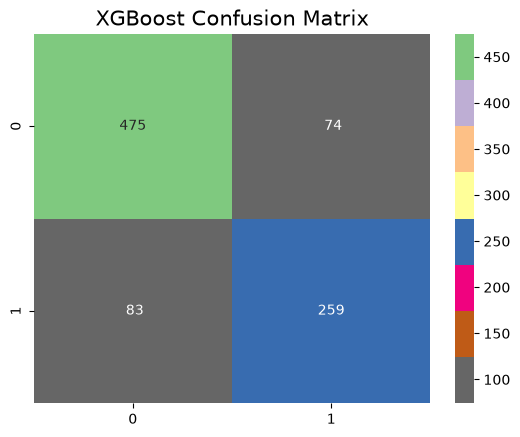

In [96]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold, train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---------- 重新准备数值型数据 ----------
# Pipeline 章节覆盖了 X 为原始 DataFrame，XGBoost 需要纯数值输入
# 这里复用前面定义的特征工程函数，重新生成编码后的数据
df_labeled = pd.read_csv("titanic/LabeledData.csv")
train_processed, scaler, age_median, fare_median = titanic_feature_engineering(
    df_labeled, onehot_pclass=False, is_train=True
)
X = train_processed.drop("Survived", axis=1)
y = train_processed["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=1,
    n_jobs=-1,
    eval_metric="mlogloss"  # 避免 warning
)

xgb_model.fit(X_train, y_train)
prediction_xgb = xgb_model.predict(X_test)

print("--------XGBoost Classifier -------")
print("The accuracy of XGBoost Classifier is", round(accuracy_score(y_test, prediction_xgb)*100, 2))

# Cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
result_xgb = cross_val_score(xgb_model, X, y, cv=kfold, scoring="accuracy")
print("The cross validated score for XGBoost Classifier is:", round(result_xgb.mean()*100, 2))

# Confusion Matrix
y_pred_xgb = cross_val_predict(xgb_model, X, y, cv=kfold)
sns.heatmap(confusion_matrix(y, y_pred_xgb), annot=True, fmt="3.0f", cmap="Accent_r")
plt.title("XGBoost Confusion Matrix", y=1, size=15)
plt.show()


**预期输出：**

```text
--------XGBoost Classifier -------
The accuracy of XGBoost Classifier is 77.24
The cross validated score for XGBoost Classifier is: 82.38
```

**预期输出（图片）：**

![xgboost示例](../assets/01_Titanic-Case-27.png)

*xgboost示例*

## lightgbm示例

--------LightGBM Classifier -------
The accuracy of LightGBM Classifier is 76.12


The cross validated score for LightGBM Classifier is: 82.71


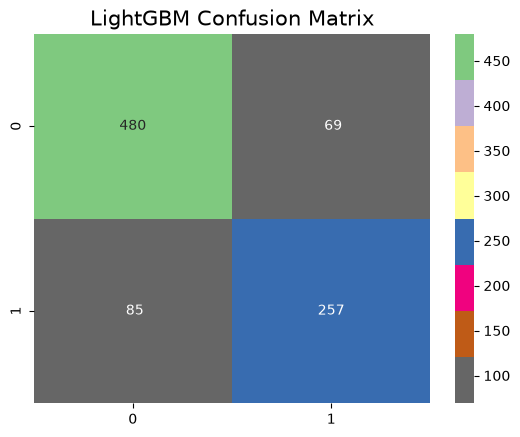

In [97]:
from lightgbm import LGBMClassifier

# LightGBM
# 调整后的LightGBM参数
lgb_model = LGBMClassifier(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=-1,  # -1表示不限制深度
    num_leaves=31,  # 考虑增加到63或127
    min_child_samples=20,  # 增加防止过拟合
    min_child_weight=0.001,  # 增加此值减少警告
    reg_alpha=0.1,  # L1正则化
    reg_lambda=0.1,  # L2正则化
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,  # 使用固定随机种子
    n_jobs=-1,
    verbosity=-1  # 减少训练输出
)

lgb_model.fit(X_train, y_train)
prediction_lgb = lgb_model.predict(X_test)

print("--------LightGBM Classifier -------")
print("The accuracy of LightGBM Classifier is", round(accuracy_score(y_test, prediction_lgb)*100, 2))

# Cross-validation
result_lgb = cross_val_score(lgb_model, X, y, cv=kfold, scoring="accuracy")
print("The cross validated score for LightGBM Classifier is:", round(result_lgb.mean()*100, 2))

# Confusion Matrix
y_pred_lgb = cross_val_predict(lgb_model, X, y, cv=kfold)
sns.heatmap(confusion_matrix(y, y_pred_lgb), annot=True, fmt="3.0f", cmap="Accent_r")
plt.title("LightGBM Confusion Matrix", y=1, size=15)
plt.show()


**预期输出：**

```text
--------LightGBM Classifier -------
The accuracy of LightGBM Classifier is 76.12
The cross validated score for LightGBM Classifier is: 82.71
```

**预期输出（图片）：**

![lightgbm示例](../assets/01_Titanic-Case-28.png)

*lightgbm示例*

# 项目总结与回顾

恭喜！你已经完成了 Titanic 生存预测的完整机器学习项目。以下是对全篇核心知识点的系统回顾。

---

## 全流程回顾

```
原始数据
   ↓
EDA（探索性数据分析）→ 理解数据分布、发现规律、识别问题
   ↓
数据预处理 → 处理缺失值、删除无关列
   ↓
特征工程 → 编码、组合特征、标准化
   ↓
模型训练 → 多算法对比 + 交叉验证
   ↓
超参数调优 → GridSearchCV
   ↓
模型部署 → Pipeline / joblib / ONNX
   ↓
预测提交
```

---

## 核心知识点总结

### 1. 数据预处理决策

| 问题 | 决策 | 原因 |
|------|------|------|
| `Age` 缺失（177 条） | 用**中位数填充** | 年龄分布有偏态，中位数比均值更稳健 |
| `Embarked` 缺失（2 条） | 用**众数填充** 或删除 | 缺失量极少，对整体影响可忽略 |
| `Cabin` 缺失（~77%） | **直接丢弃** | 缺失率过高，填充无意义，反而引入噪声 |
| `PassengerId/Name/Ticket` | **直接丢弃** | 与生存预测无直接关联，或难以提取有效特征 |
| `Fare` 右偏分布 | **取 log 变换** | 压缩长尾，使分布更接近正态，有利于模型学习 |

### 2. 特征工程要点

- **Sex**：二值类别，Label Encoding（0/1）即可
- **Embarked**：无序多类别，One-Hot Encoding 避免引入虚假顺序关系
- **Pclass**：有序类别，保留整数 1/2/3 或 One-Hot 均可
- **FamilySize**：组合特征 `SibSp + Parch + 1`，比单独使用更有信息量
- **IsChild**：业务特征 `Age < 16`，捕捉 "儿童优先救援" 的决策规则

### 3. 模型选择经验

在本项目的数据集上，各算法表现排序大致为：

```
Random Forest ≈ XGBoost ≈ LightGBM > SVM ≈ Logistic Regression > KNN > Naive Bayes
```

> 注意：这个排序**仅针对本数据集**，不同数据集上表现可能完全不同。

### 4. 关键正确性保障

- **训练/测试集的预处理方式必须完全一致**：Scaler 只能用训练集 `fit`，测试集只做 `transform`
- **交叉验证时预处理不能提前做**：否则会发生数据泄露，评估结果过于乐观
- **Pipeline 是解决上述问题的最佳方案**：将预处理 + 模型打包，CV 时每个 fold 自动隔离

---

## 常见陷阱与避坑指南

1. **不要在 `train_test_split` 之前做全局标准化** — 测试集信息会泄露给训练集
2. **不要在测试集上调用 `fit_transform`** — 应该只用 `transform`
3. **不要混用评估口径** — Hold-out 准确率和 CV 准确率不要直接对比
4. **不要硬编码索引** — 数据经删除/排序后索引会变，用条件筛选更安全
5. **保存模型时记得保存预处理器** — 只保存模型文件，部署时特征不一致会导致预测错误

---

## 下一步学习建议

- **深入理解特征工程**：尝试从 `Name` 中提取 `Title`（Mr/Mrs/Miss/Master），这是一个强特征
- **处理类别不平衡**：Titanic 数据集的存活率约 38%，可尝试 `class_weight` 或采样策略
- **模型集成**：尝试 Stacking / Voting，结合多个模型的预测结果
- **特征重要性分析**：用 `RandomForest.feature_importances_` 或 SHAP 解释模型决策
- **AutoML**：尝试 `AutoGluon` 或 `FLAML`，看看自动化工具能达到什么水平

---

## 参考资源

- [Kaggle Titanic Competition](https://www.kaggle.com/competitions/titanic)
- [sklearn Pipeline 官方文档](https://scikit-learn.org/stable/modules/compose.html#pipeline)
- [sklearn ColumnTransformer 官方文档](https://scikit-learn.org/stable/modules/compose.html#column-transformer)
- [Kaggle EDA 参考 Notebook](https://www.kaggle.com/code/abhayparashar31/titanic-complete-analysis-prediction)
